# DeepSeasons experiment `Y621s`

**Europe T2M, seasonal-mean forecasts (inputs T850 + T2M).**

Part of the DeepSeasons repository. Run from the `notebooks/` folder after installing the environment and downloading the ERA5 input data as described in the top-level `README.md`. Stored outputs are from the run used for the paper.


In [4]:
%env PYTORCH_ENABLE_MPS_FALLBACK=1

env: PYTORCH_ENABLE_MPS_FALLBACK=1



# SST.Y621s

Predictions of monthly mean SST from SST
Generalization to N fields
Using SST, T2M, Z500, U850, V850
Global Tropics 

Uses parameters obtained fro senstivity experiments
 
Using climformer from library

Version with optional comparison with dynamical models
Version with verification standard
Version with strong discount and only one lag [1,2,3,4]
Tprediction up to 12 months

Based on PYTORCH

* Duplicate of X620 plus comparison with dynamical forecasts

* Strong discount [0.2]
  
* New time scheme for the forecasts


In [5]:
import os,sys
import math
import pickle
import tabulate as tab
import datetime
import time as tm
import random

import matplotlib.pyplot as plt
from collections  import namedtuple


import numpy as np
import scipy.linalg as sc
import scipy.signal as sig
import numpy.linalg as lin
from scipy import stats
# from scipy.signal import argrelextrema

from alive_progress import alive_bar
import time

import xarray as xr
import pandas as pd

# import numpy.polynomial.polynomial as poly

# AI Imports
from sklearn import datasets		# To Get iris dataset
from sklearn import svm   
from sklearn.cluster import KMeans, AgglomerativeClustering
import scipy.io
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
# import transformers as tr
# import torch.nn.functional as F

# ---------------------------------------------------------------------------
# Repository paths: libraries (Zapata, AIModels) are bundled in ../lib.
# Data locations are set in lib/dspaths.py or via the environment variables
# DEEPSEASONS_DATA, DEEPSEASONS_SEASONAL, DEEPSEASONS_WORKDIR (see README).
# ---------------------------------------------------------------------------
from pathlib import Path
_repo = Path(os.environ.get('DEEPSEASONS_ROOT', Path.cwd().resolve().parent))
sys.path.insert(0, str(_repo / 'lib'))
import dspaths
dspaths.setup(chdir=True)          # adds lib/ and lib/Zapata to sys.path, cd to WORK_DIR
DATA_DIR = dspaths.DATA_DIR
homedir = os.path.expanduser("~")

# import klus.algorithms as al
# # import d3s.domain as domain
# import klus.kernels as kernels
# # import d3s.tools as tools

import zapata.computation as zcom
import zapata.data as zd
import zapata.lib as zlib
import zapata.mapping as zmap
import AIModels.AIutil as zai
import AIModels.AIClasses as zaic
import AIModels.ClimFormer as zcf
import AIModels.UtilPlot as utp
import AIModels.ModelTraining as mtr
import AIModels.Validation as val
# import AIModels.LocalInformer as ltr
import AIModels.Informer.modeling_informer as ltr
import AIModels.Informer.configuration_informer as ctr

today_date = datetime.date.today().strftime("%Y-%m-%d")

# from scipy.spatial import distance
# from sklearn.model_selection import GridSearchCV
# from sklearn.neighbors import KernelDensity

env = zlib.get_environment_info('interpreter')
print(f'\n\nNotebook operating in ENV {env} -- {today_date}\n')

#%pdb
%load_ext autoreload
%autoreload 2
%matplotlib inline


Root Directory for Data  ~
Working Directory set to  ~/SST-AI


Notebook operating in ENV ~/anaconda3/envs/AI2-2026/bin/python -- 2026-09-22

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Input data from ERA5

Definiton of Areas and Period

Choice of encoding and variance retained

## Prepare data

The training data is read using a definition of a class that defines which data are read in which field, and how many EOF, and which region of the word is selected, including level. This class is contained into the *AIutil* class module and is called **Field**.


In [6]:
# Configure case

case = 'Y621s'


shift = 'ERA5'      # Choose data period
SMOOTH = True       # Apply seasonal filter
period = 'ANN'      # Annual or season
comp_diff = False   # predict differences

data_name= case 
normalization = 'anom'  #Normalization for the EOF
write_result = False    # Write esults to netcdf file
only_valtrain_eof = True  # Use only training and validation for EOF
clim_train = True      #  Compute anomalies only with respect the training data
verify_dyn = True  #  Verify against dynamical forecasts
choose_device = 'MPS' #'GPU'   # choose if 'CPU' or 'GPU'
# Use SVD encoding
encode_svd = True
#Choose number of SVD to ratain
var_retained = None # 0.99#.99#

#Select period for EOF:
if only_valtrain_eof:
    #Use only training and validation for EOF:
    if SMOOTH:
        eof_interval =['1940-03-01','2015-12-01']
    else:
        eof_interval =['1940-01-01','2015-12-01']
else:
    eof_interval = None   # Use all data

if clim_train:
    clim_int = eof_interval
else:
    clim_int = None
    
#Select variables:

# [SST,T2M], Smooth, [8,16]
# Z200 = zaic.Field('Z',['200'],'WORLD',15, dropX=True)
Z500 = zaic.Field('Z',['500'],'WORLD',25,dropX=False)
# V850 = zaic.Field('V',['850'],'TROPIC',15, dropX=True)
U850 = zaic.Field('U',['850'],'EUROPE',0.95, dropX=True)
T850 = zaic.Field('T',['850'],'EUROPE',0.95, dropX=True)
U1000 = zaic.Field('U',['1000'],'TROPIC',15, dropX=True)
# U1000 = zaic.Field('U',['1000'],'TROPIC',15, dropX=True)
# Z850 = zaic.Field('Z',['850'],'EUROPE',12)
# Z500 = zaic.Field('Z',['500'],'NH-ML',15)
T2M = zaic.Field('t2m',['t2m'],'EUROPE',0.95)
U10S = zaic.Field('U10',['U10'],'TROPIC',15, dropX=True)
MTNLWRF = zaic.Field('MTNLWRF',['MTNLWRF'],'TROPIC',25, dropX=True)
SP = zaic.Field('SP',['SP'],'WORLD',15,dropX=True)
SST = zaic.Field('SST',['SST'],'GLOBAL',15,dropX=False)
InputVars =  [T850,T2M] #[  MTNLWRF, SST, U850, SP]
PredictVars = [T850, T2M] #[  MTNLWRF, SST, U850, SP]

Score_Field = 'T2MT2M'


# Write case configuration
caseid =  {'case':case, 'version':'V5', 'SMOOTH':SMOOTH, 'normalization':normalization,\
           'only_valtrain_eof':only_valtrain_eof, 'eof_interval':eof_interval,\
           'shift':shift,'period':period, 'InputVars':InputVars,'PredictVars':PredictVars}


The input variable are then collected within a dictionary **INX** that contains all the variables and the information that are necessary for the analysis. Another Dictionary **caseid** contains the basic information, identifying the options and the configuration of these analysis.

In [7]:
#Input variables data base
invar_dict = {'period':'ANN', 'version':'V5', 'SMOOTH':SMOOTH, 'normalization':normalization, 'detrend':False,\
              'eof_interval':eof_interval, 'clim_eof_interval':clim_int, 'shift':'ERA5', 'case':case, 'datatype':'Source_data','location':DATA_DIR}
INX=zai.make_data_base(InputVars, **invar_dict)

Directory  ~/ERA5_DATA/DATA_CACHE  Already Exists
Selected data from 1940-01-01T00:00:00.000000000 to 2022-12-01T00:00:00.000000000 

Use Greenwich centered coordinates with centlat=0
Selecting field T for level 850 and area EUROPE
{'dropnan': False, 'detrend': False}
Created data Matrix X, stacked along dimensions ('lat', 'lon') 
Option DropNaN False -- Shape of Xmat (45241, 996)
make_matrix: -- Computing climatology from 1940-03-01 to 2015-12-01
EOF interval defined -- Using data from 1940-03-01 to 2015-12-01
make_eof: -- EOF interval defined -- Using data from 1940-03-01 to 2015-12-01
make_eof: -- EOF interval defined -- Using data from 0 to 909
Target Variance 0.95
  Number of SVD modes retained 14, rank of matrix 898
  Variance Retained 0.95 out of possible 909 modes
Use cofficients non standardized directly from projection on EOF
Dropping X matrix
Added field `T` with identification `T850` to data base
Directory  ~/ERA5_DATA/DATA_CACHE  Already Exists
Selected data from 1940-01-0

In [8]:
#Predicted variables data base
pred_dict =  {'period':'ANN', 'version':'V5', 'SMOOTH':SMOOTH, 'normalization':normalization, 'detrend':False,\
              'eof_interval':eof_interval, 'shift':'ERA5', 'case':case, 'datatype':'Target_data','location':DATA_DIR}

#Save space
# PDX=zai.make_data_base(PredictVars, **pred_dict)
PDX = INX

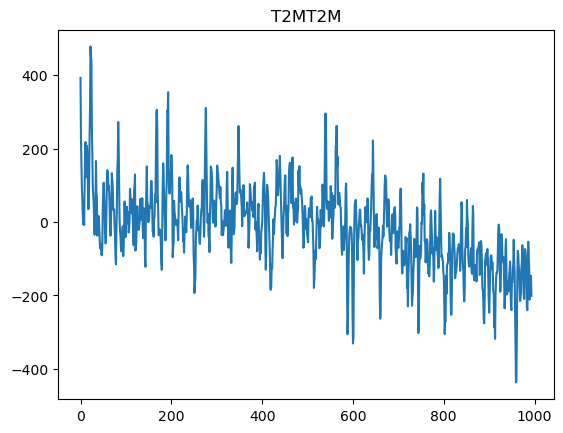

In [9]:
#Verification variables data base
# SSTver = zaic.Field('SST',['SST'],'TROPIC',math.inf)

# ver_dict = {'period':'ANN', 'version':'V5', 'SMOOTH':SMOOTH, 'normalization':normalization, \
#                    'shift':'ERA5', 'case':case, 'datatype':'Target_data','location':DATA_DIR}
# #Save space
# VEX=zai.make_data_base([SSTver], **ver_dict)
plt.plot(INX[Score_Field]['vdat'][0,:])
plt.title(Score_Field)
plt.show()

In [10]:
# Obtain time dates from data chosen
field1 = Score_Field
fd = INX[field1]['X'].A.time.data[0]
fl = INX[field1]['X'].A.time.data[-1]
pd.Timestamp(fd), pd.Timestamp(fl)
data_time = pd.date_range(start=fd, end=fl, freq='1MS')
data_time_str = data_time.strftime('%Y-%m-%d')

In [11]:
# Configure AI Model
# Find total number of features and boundaries
num_features_src, m_lim_src = zai.make_features(INX) 
# Find total of features in target
num_features_tgt, m_lim_tgt = zai.make_features(PDX) 


Processing field T that is Source_data
Limit for T is 14

Processing field t2m that is Source_data
Limit for t2m is 26
Total number of features  40

Processing field T that is Source_data
Limit for T is 14

Processing field t2m that is Source_data
Limit for t2m is 26
Total number of features  40


In [12]:
params ={'TIN':18,'MIN':num_features_src,'T':12,'K':num_features_tgt,'EPOCHS':400,'RESTART':False, 'D_DIM':256, 'Tpredict':12,
         'FFN_DIM':256,'ENC_Heads':8,'DEC_Heads':8, 'enc_dec_layers':1, 'scaling':'MaxMin',
         'LR':1*0.00005,'WD':0.01,'savefile':None}
params['savefile'] = f"informer_{case}_{normalization}_{params['enc_dec_layers']}_{params['D_DIM']}_{params['TIN']}_{SMOOTH}"
params['discount'] = 1.0 #1.0#0.9
subcase = 1
subcase_var = 299

TIN = params['TIN']  # Number of input timestep47
MIN = params['MIN']   # Number of input features
T = params['T']    # Number of output timesteps
K = params['K']    # Number of predicted features
num_epochs = params['EPOCHS'] 
RESTART = params['RESTART']
Tpredict = params['Tpredict']
LAGS =[1,2,3,4]

params['lags'] = LAGS
CONTEXT = TIN - max(LAGS)
assert CONTEXT > 0, 'Value of LAGS wrong'
print(f' Chosen context is {CONTEXT}, for max(lags)  {max(LAGS)}')

learning_rate = params['LR'] 
file = 'MOD_' + params['savefile'] + '.pt'
FIGfile =  'FIG_' + params['savefile'] + '.pdf'

batch_size = 16
# Reproducibility
torch.manual_seed(17553984)

match choose_device:
    case 'CPU':
        device = torch.device('cpu')
        t_type = torch.float32
    case 'MPS':
        device = torch.device('mps')
        t_type = torch.float32
    case _:
        device = torch.device('cpu')
        t_type = torch.float32
torch.set_default_dtype(t_type)
params['t_type'] = t_type
params['device'] = device
#
#
# The Convention for indeces is that they point to the real date.
# I python ranges need to be defined then it must take into account the extra 1
data_time.get_loc(fd)

start_date = data_time_str[0]
end_training = '2005-12-01'

start_val = '2006-01-01'
end_val = '2015-12-01'

test_start = '2016-01-01'
test_end = '2022-12-01'


# end_training = '2010-12-01'

# start_val = '2011-01-01'
# end_val = '2016-12-01'

# test_start = '2017-01-01'
# test_end = '2022-12-01'

print(f'Training \tfrom \t{start_date} \tto \t{end_training} \nValidation \tfrom \t{start_val} \tto \t{end_val} \nTesting \tfrom \t{test_start} \tto \t{test_end}\n')

train_period_start = data_time.get_loc(start_date)
train_period_end = data_time.get_loc(end_training)
val_period_start = data_time.get_loc(start_val)
val_period_end = data_time.get_loc(end_val)
test_period_start = data_time.get_loc(test_start)
test_period_end = data_time.get_loc(test_end)

params |= {'start_date':start_date,'end_training':end_training, 'start_val':start_val,'end_val':end_val,'test_start':test_start,'test_end':test_end, \
        'train_period_start':train_period_start,'train_period_end':train_period_end, 'val_period_start':val_period_start, 'val_period_end':val_period_end,'test_period_start':test_period_start, 'test_period_end':test_period_end}


print(f'Absolute Indices for \nTraining \t{train_period_start}\tto \t{train_period_end}\nValidation \t{val_period_start}\tto \t{val_period_end}\nTest \t\t{test_period_start}\tto \t{test_period_end}\n')
print(f'Range Indices for \nTraining \t{train_period_start}\tto \t{train_period_end+1}\nValidation \t{val_period_start}\tto \t{val_period_end+1}\nTest \t\t{test_period_start}\tto \t{test_period_end+1}\n')


print(f'Data Extent in Training {(train_period_end-train_period_start)+1}')
print(f'Data Extent in Validation {(val_period_end-val_period_start)+1}')
print(f'Data Extent in Test {(test_period_end-test_period_start)+1}')


# Define range indices for forecasting sequences
params['train_first_fcs'] = TIN                           # First forecasted month for first forecast 
params['train_last_fcs'] = params['train_period_end'] - Tpredict   + 1     # First forecasted month for last forecast 
params['val_first_fcs'] = params['val_period_start']  + TIN    
params['val_last_fcs'] = params['val_period_end'] - Tpredict    + 1   
params['test_first_fcs'] = params['test_period_start']  + TIN
params['test_last_fcs'] = params['test_period_end'] - Tpredict    + 1    
print(f'Starting indices for the sequences in training and forecasts\n')
print(f"TESTING -- \tFirst forecasted month for first forecast {params['test_first_fcs']} \t--> {data_time[params['test_first_fcs']]}\
                    \n\t\tFirst forecasted month for last forecast {params['test_last_fcs']} \t--> {data_time[params['test_last_fcs']]}")
print(f"TRAINING -- \tFirst forecasted month for first forecast {TIN}\t--> {data_time[TIN]}\
                    \n\t\tFirst forecasted month for last forecast {params['train_last_fcs']}\t--> {data_time[params['train_last_fcs']]}")

print(f'Number of forecast cases in each epoch')
print(f"Forecast in Training {params['train_last_fcs']-params['train_first_fcs'] +1 }")
print(f"Forecast in Validation {params['val_last_fcs']-params['val_first_fcs'] +1 }")
print(f"Forecast in Test {params['test_last_fcs']-params['test_first_fcs'] +1 }")

 Chosen context is 14, for max(lags)  4
Training 	from 	1940-03-01 	to 	2005-12-01 
Validation 	from 	2006-01-01 	to 	2015-12-01 
Testing 	from 	2016-01-01 	to 	2022-12-01

Absolute Indices for 
Training 	0	to 	789
Validation 	790	to 	909
Test 		910	to 	993

Range Indices for 
Training 	0	to 	790
Validation 	790	to 	910
Test 		910	to 	994

Data Extent in Training 790
Data Extent in Validation 120
Data Extent in Test 84
Starting indices for the sequences in training and forecasts

TESTING -- 	First forecasted month for first forecast 928 	--> 2017-07-01 00:00:00                    
		First forecasted month for last forecast 982 	--> 2022-01-01 00:00:00
TRAINING -- 	First forecasted month for first forecast 18	--> 1941-09-01 00:00:00                    
		First forecasted month for last forecast 778	--> 2005-01-01 00:00:00
Number of forecast cases in each epoch
Forecast in Training 761
Forecast in Validation 91
Forecast in Test 55


The training, validation, and test are then selected in the following. The time boundaries are absolute limits for this case. They do not take into account either the input sequence or the prediction time Tpredict.

The dictionary **params** contain the time information in the series that correspond to the time location in the data base.

## Plot Input Data

In [13]:
 zai.transform_strings(k for k in INX.keys() if 'X' in INX[k].keys())

['T2M']

T2MT2M
 Opening figure , 1 rows and 1 cols 

Ten Contours automatic


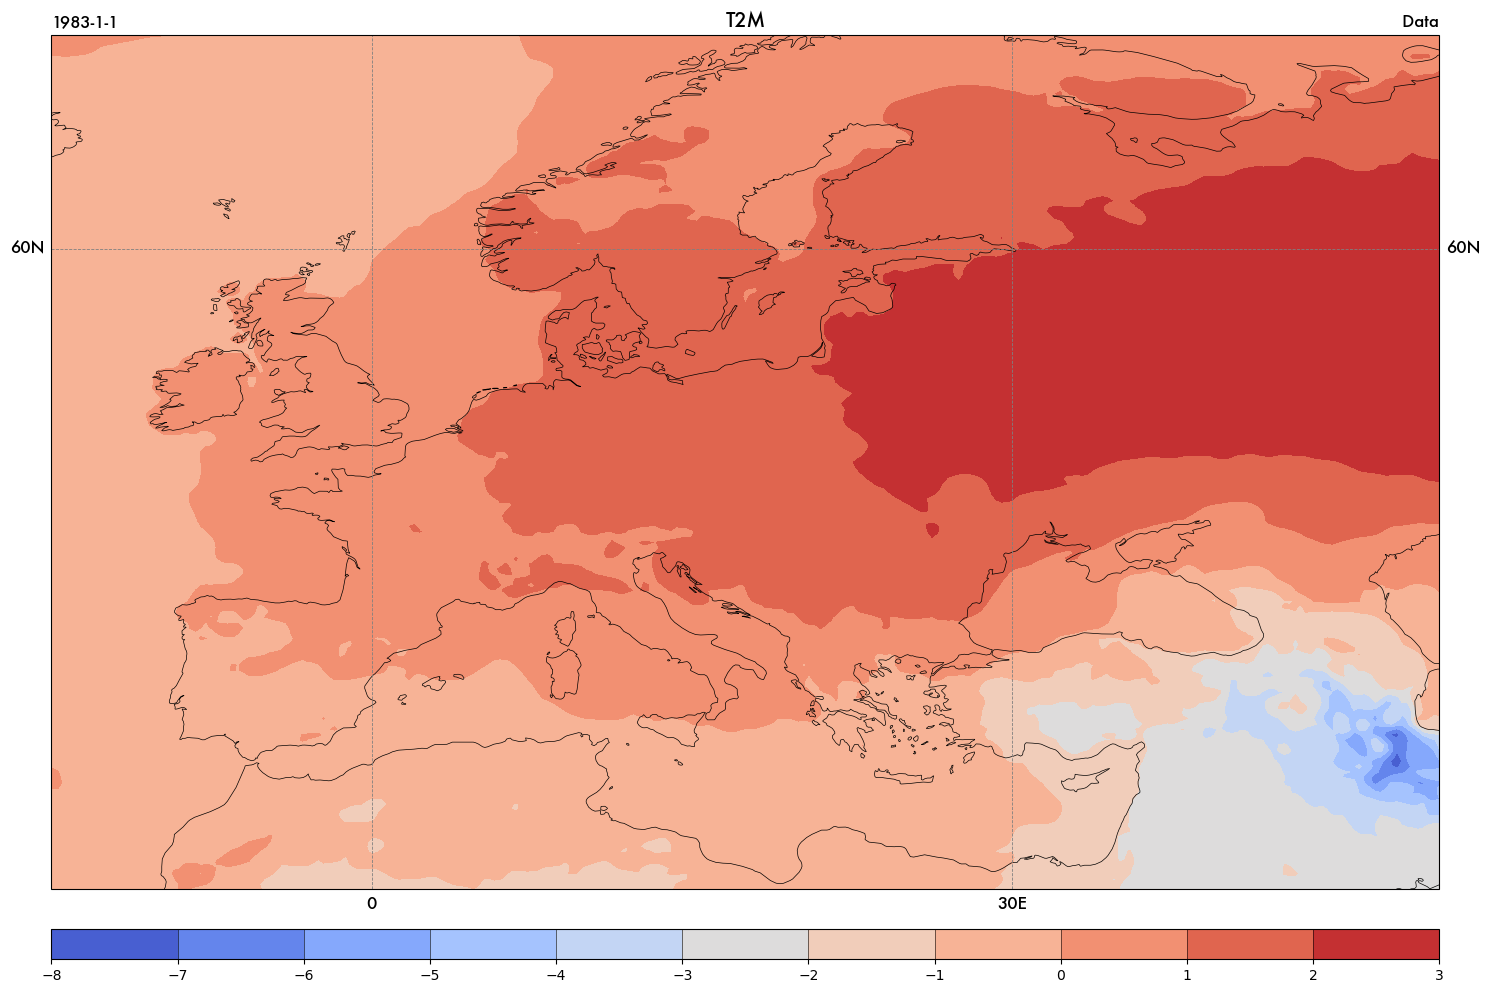

In [14]:
slim=4.0
cont1=[-slim,slim,0.5]
cont2=[-slim,slim,0.5]
cont1=[]
cont2=[]
cont3=[]
label1 = ' Data'
label2 = '1983-1-1'
label3 = '1998-1-1'

# Filter the keys to only include those that contain 'X'
inx_keys =  [k for k in INX.keys() if 'X' in INX[k].keys() ]
print(inx_keys[0])
# Initialize the figure with the number of filtered keys
fig, ax, pro = zmap.init_figure(len(inx_keys), 1, 'Atlantic', constrained_layout=False, figsize=(24,12))

# Loop over the filtered keys
for i, key in enumerate(inx_keys):
    X, arealat, arealon, centlon = zai.select_field(INX, key)
   
    # Use a single axis if there's only one, otherwise use the corresponding subplot
    axm = ax if len(inx_keys) < 2 else ax[i]
    
    handle = zmap.xmap(
        X.A.sel(time=label2).unstack(), cont1, pro,
        ax=axm,
        refline=None,
        c_format='{:4.2f}',
        data_cent_lon=centlon,
        xlimit=(arealon[0], arealon[1]),
        ylimit=(arealat[1], arealat[0]),
        title={'maintitle': zai.transform_strings([key])[0], 'lefttitle': label2, 'righttitle': label1},
        cmap='coolwarm',
        contour=False
    )
    
    zmap.add_colorbar(fig, handle['filled'], axm, label_size=10, edges=True)

# Adjust the subplots and save the figure
fig.subplots_adjust(wspace=0.1, hspace=0.3)
labfile = f'{data_name}SST{period}.pdf'
plt.savefig(labfile, orientation='landscape', format='pdf')
plt.show()

## Plot EOF coefficients of input fields

T (14,) (14, 994)
t2m (26,) (26, 994)


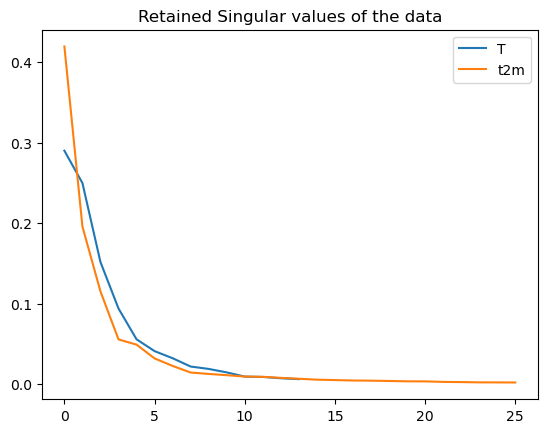

In [15]:
for i in INX.keys():
    print(INX[i]['field'],INX[i]['sdat'].shape,INX[i]['vdat'].shape)
    plt.plot(INX[i]['sdat']**2/sum(INX[i]['sdat']**2),label=INX[i]['field'])

plt.legend()
plt.title('Retained Singular values of the data')
plt.show()

select_field_eof ---> Extracting EOF data for t2m
 Opening figure , 2 rows and 1 cols 

Ten Contours automatic
Ten Contours automatic


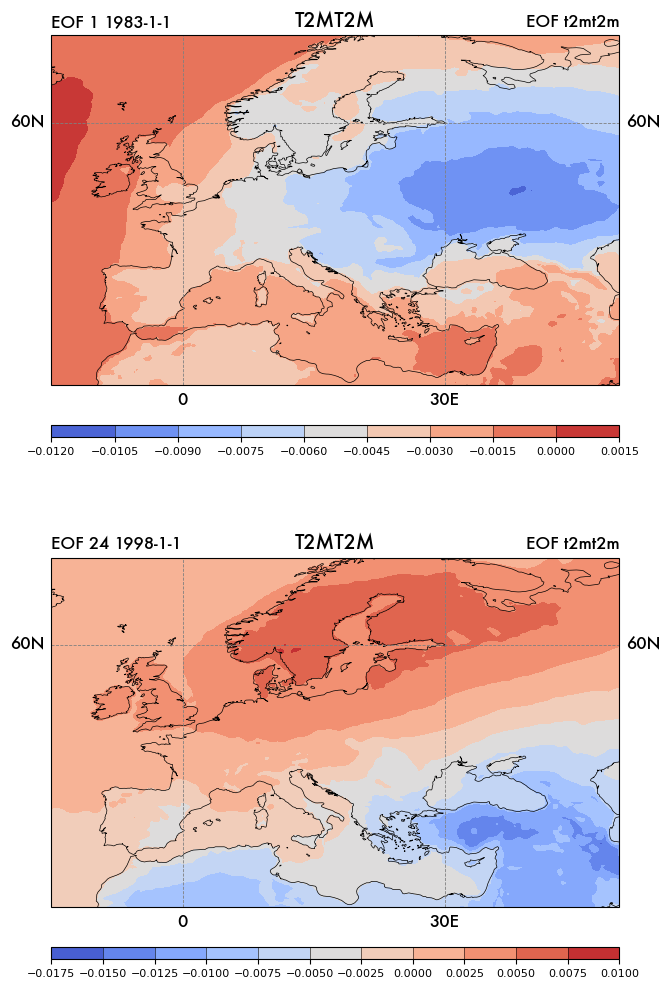

In [16]:
#Plot first EOF of input fields
plfield = Score_Field
Nplfield = INX[plfield]['mr']
udat,_,_ = zai.select_field_eof(INX,plfield)
nameeof = zai.select_field_key(INX,plfield,'field')+zai.select_field_key(INX,plfield,'level')
utest = INX[plfield]['X'].A.isel(time=slice(0,Nplfield)).copy(data=udat[:,0:Nplfield])
arealon = zai.select_field_key(INX,plfield,'arealon')
arealat = zai.select_field_key(INX,plfield,'arealat')
plpro = 'Pacific'
if INX[plfield]['area'] == 'EUROPE':
    plpro = 'Atlantic'
slim=4.0
cont1=[-slim,slim,0.5]
cont2=[-slim,slim,0.5]
cont1=[]
cont2=[]
label1 = 'EOF ' + nameeof
label2 = f'EOF 1 1983-1-1'
label3 = f'EOF {Nplfield-2} 1998-1-1'
    
fig,ax,pro=zmap.init_figure(2,1,plpro, constrained_layout=False, figsize=(12,12) )
handle=zmap.xmap(utest.isel(time=0).unstack(),cont1, pro, ax=ax[0],refline=None, c_format='{:4.2f}',data_cent_lon=INX[plfield]['centlon'],\
                       xlimit=(arealon[0],arealon[1]), ylimit=(arealat[1],arealat[0]),
                 title={'maintitle':Score_Field, 'lefttitle':label2,'righttitle':label1},cmap='coolwarm',contour=False)
zmap.add_colorbar(fig, handle['filled'], ax[0], label_size=8,edges=True)
# ax[1].projection = zmap.choose_projection('Atlantic')
han1=zmap.xmap(utest.isel(time=1).unstack(), cont2, plpro, ax=ax[1], refline=None,c_format='{:4.2f}',data_cent_lon=INX[plfield]['centlon'],\
                       xlimit=(arealon[0],arealon[1]),ylimit=(arealat[1],arealat[0]),
               title={'maintitle':Score_Field, 'lefttitle':label3,'righttitle':label1},cmap='coolwarm',contour=False)
zmap.add_colorbar(fig, han1['filled'], ax[1],label_size=8,edges=True)
fig.subplots_adjust(wspace=0.1,hspace=0.3)
labfile =  f'EOF{data_name}SST{period}.pdf'
# plt.savefig(labfile, orientation='landscape',  format='pdf')
plt.show()

## Data Preparation and Input parameters

The total number of features, and the limit in the database, for the different fields are then computed in **make_features**.

In [17]:
# Configure AI Model
# Find total number of features and boundaries
num_features_src, m_lim_src = zai.make_features(INX) 
# Find total of features in target
num_features_tgt, m_lim_tgt = zai.make_features(PDX) 


Processing field T that is Source_data
Limit for T is 14

Processing field t2m that is Source_data
Limit for t2m is 26
Total number of features  40

Processing field T that is Source_data
Limit for T is 14

Processing field t2m that is Source_data
Limit for t2m is 26
Total number of features  40


# Configure the model

## Define Time limit taking into account Tpredict and predictions

The model can have two different future times. *T*  is the time on which the model is trained. The second time is Tpredict. This is the extent of the prediction that is going to be produced by the greedy inference after the model is being evaluated.

The prediction starting time can go only to Tpredict distance from the end training.
And the first forecast start at time *start_test + TIN*


In [18]:

# Split the dataset into train, validation, and test sets
train_size = (train_period_end-train_period_start)+1
val_size = (val_period_end-val_period_start)+1
test_size = (test_period_end-test_period_start)+1

tot_size = (test_period_end-train_period_start)+1
print(f'Train {train_size}, Validation {val_size}, Test {test_size}')
print(f'Check {train_size+val_size+test_size} <---> {tot_size}')

# Split the data into train, validation, and test sets
train_data, val_data, test_data, _ = zai.make_data(INX,params)
tgt_train_data, tgt_val_data, tgt_test_data, _ = zai.make_data(PDX,params)    

#Optionally use differences
if comp_diff:
    train_data, trIC = zai.compute_increments(train_data,axis=0)
    val_data, vaIC = zai.compute_increments(val_data,axis=0)
    test_data, teIC = zai.compute_increments(test_data,axis=0)
    tgt_train_data, _ = zai.compute_increments(tgt_train_data,axis=0)
    tgt_val_data, _ = zai.compute_increments(tgt_val_data,axis=0)
    tgt_test_data, _ = zai.compute_increments(tgt_test_data,axis=0)


print(f'\nTensors Train {train_data.shape}, Validation {val_data.shape}, Test {test_data.shape}')
print(f'Check Tensors {train_data.shape[0]+val_data.shape[0]+test_data.shape[0]}')



Train 790, Validation 120, Test 84
Check 994 <---> 994

Processing field T that is Source_data
select_field_eof ---> Extracting EOF data for T
vdat (14, 994)
Using MaxMin scaling
Added field T850 to feature input data
Index for field T are 0 and 14

Using MaxMin scaling
Using  14  EOFs for 0.9501738680834118 variance retained

Processing field t2m that is Source_data
select_field_eof ---> Extracting EOF data for t2m
vdat (26, 994)
Using MaxMin scaling
Added field T2MT2M to feature input data
Index for field t2m are 14 and 40

Using MaxMin scaling
Using  26  EOFs for 0.951274163972658 variance retained
Training data shape torch.Size([790, 40])
Validation data shape torch.Size([120, 40])
Testing data shape torch.Size([84, 40])

Processing field T that is Source_data
select_field_eof ---> Extracting EOF data for T
vdat (14, 994)
Using MaxMin scaling
Added field T850 to feature input data
Index for field T are 0 and 14

Using MaxMin scaling
Using  14  EOFs for 0.9501738680834118 variance r

In [19]:
# Create instances of the time features
tim_train = zai.create_time_features(data_time[:train_size+1], 0, device)
tim_val = zai.create_time_features(data_time[train_size:train_size+val_size+1], 0, device)
tim_test = zai.create_time_features(data_time[train_size+val_size:tot_size+1], 0, device)

# Create instances of the custom dataset for train, validation, and test
train_dataset = zcf.TimeSeriesDataset(train_data, tgt_train_data, TIN, MIN, T, K, time_features=tim_train )
val_dataset = zcf.TimeSeriesDataset(val_data, tgt_val_data, TIN, MIN, T, K, time_features=tim_val )
test_dataset = zcf.TimeSeriesDataset(test_data, tgt_test_data,TIN, MIN, T, K, time_features=tim_test )

# Create data loaders for train, validation, and test sets
train_dataloader = DataLoader(train_dataset,  batch_size=batch_size)
val_dataloader = DataLoader(val_dataset, batch_size=batch_size)
test_dataloader = DataLoader(test_dataset,batch_size=batch_size)

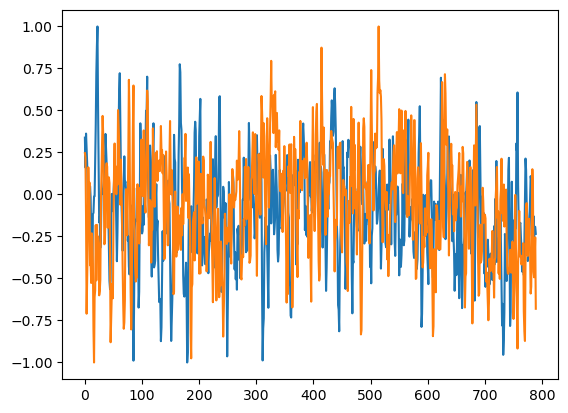

In [20]:

#Create dataloader configuration for prediction
# Only for the test dataset
# Create instances of the custom dataset for train, validation, and test
# pred_dataset = zaic.TimeSeriesDataset(test_data, tgt_test_data, tim_test,TIN, MIN, Tpredict, K)

# # Create data loaders for train, validation, and test sets
# pred_dataloader = DataLoader(pred_dataset,batch_size=batch_size)
plt.plot(train_data[:,0].cpu().numpy())
plt.plot(train_data[:,4].cpu().numpy())
plt.show()


### Configuration

In [21]:
# Initializing an Informer configuration with 12 time steps for prediction
# loss_weight can be defined for the loss function as a tensor (batch_size, T), with weights summing to 1
configuration = ctr.InformerConfig(prediction_length=T, context_length = CONTEXT, 
                distribution_output = 'student_t', loss = 'nll', 
                input_seq = TIN,
                input_size = num_features_src,
                output_size = num_features_tgt,
                lags_sequence = LAGS,
                scaling = 'std',
                num_dynamic_real_features = 0, 
                num_static_real_features = 0,
                num_static_categorical_features = 0,
                num_time_features  = 3,
                cardinality = None,
                embedding_dimension=None,
                pos_embedding_dim = None, 
                d_model= params['D_DIM'],
                encoder_ffn_dim = params['FFN_DIM'],
                decoder_ffn_dim = params['FFN_DIM'],
                encoder_attention_heads = params['ENC_Heads'],
                decoder_attention_heads = params['DEC_Heads'],
                encoder_layers = params['enc_dec_layers'],
                decoder_layers = params['enc_dec_layers'],
                output_hidden_states = True,
                is_encoder_decoder = True,
                activation_function = 'relu',
                dropout = 0.2,
                encoder_layerdrop = 0.1,
                decoder_layerdrop= 0.1,
                attention_dropout= 0.1,
                activation_dropout= 0.1,
                num_parallel_samples= 50,
                init_std = 0.02,
                use_cache = True,
                attention_type= 'full',
                sampling_factor = 5,
                discount = params['discount'],
                Tpredict = Tpredict,
                distil = False)

# Set random seed
torch.manual_seed(17553984)

# Randomly initializing a model (with random weights) from the configuration
# model = zcf.ClimFormer(configuration)
model = ltr.InformerForPrediction(configuration)
# 
# Accessing the model configuration
configuration = model.config

configuration.context_length

14

## Training model

In [22]:
configuration.feature_size

243

In [23]:
# Discounting 
print(f'Discounting set at {[configuration.discount**i for i in range(Tpredict+1)]}')


Discounting set at [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]


In [24]:
# criterion = nn.L1Loss()

#Optimizer
optim1 = optim.Adam(model.parameters(),lr=2*learning_rate,weight_decay=params['WD'],amsgrad=True)
# optim1 = torch.optim.SGD(model.parameters(), lr=2*learning_rate, momentum=0.8)
# optim3 = torch.optim.SGD(model.parameters(), lr=2*learning_rate, momentum=0.5)
optim2 = optim.AdamW(model.parameters(),lr=learning_rate,weight_decay=params['WD'],amsgrad=True)
# optim4 = optim.AdamW(model.parameters(),lr=learning_rate,weight_decay=params['WD'])

criterion = None
#Number of parameters
print(f'The model has {zai.count_parameters(model):,} trainable parameters')
# model

The model has 1,211,512 trainable parameters


In [25]:
%%time
# train and validate model
clip=1
check_val = 1
patience=10

if RESTART:
    model.load_state_dict(torch.load(file))
else:
    import subprocess
    subprocess.run(["rm", "*.pt"])
    print("All *.pt files removed")
    
best_val_loss = float("inf")
num_epochs = params['EPOCHS']
loss_tr = []
loss_va = []

optims = [ optim1, optim2]
rates = [learning_rate, learning_rate, learning_rate]

for i in range(len(optims)):    

    print(optims[i])
    early_stopping = zaic.EarlyStopping(patience=patience, verbose=True)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optims[i], patience=patience/2, factor=0.5, mode="min")
    for epoch in range(num_epochs):

        model.to(device)

        # Train the model
        trained_model,losstr = mtr.train_model(model, epoch,  train_dataloader, optims[i],
                                lr=rates[i], patience=patience, clip=1.0,device=device,criterion=criterion)
        loss_tr.append(losstr)
        if epoch % check_val == 0:
            trained_model,lossva = mtr.validate_model(model, epoch,  val_dataloader, 
                                lr=rates[i], patience=patience, clip=1.0,device=device,criterion=criterion)
           
            loss_va.append(lossva)
            torch.nn.utils.clip_grad_norm_(model.parameters(), clip)
            scheduler.step(lossva)
            print(f' Scheduler learning rate: {scheduler.get_last_lr()}')
            # Early stopping
            if early_stopping(lossva):
                print(f"Early stopping at epoch {epoch + 1}")
                break

            if lossva < best_val_loss:
                best_val_loss = lossva
                print(f'Saving file to {file} at loss {lossva:.5f}')
                torch.save(model.state_dict(), file)

            if epoch % 2 == 0:
                print(f'\t Epoch {epoch} --   Train Loss: {losstr:.5f} --- Valid Loss: {lossva:.5f}')

            
    # Load the best model
    model.load_state_dict(torch.load(file))

All *.pt files removed
Adam (
Parameter Group 0
    amsgrad: True
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0.01
)


rm: *.pt: No such file or directory


 Scheduler learning rate: [0.0001]
Saving file to MOD_informer_Y621s_anom_1_256_18_True.pt at loss 5.77450
	 Epoch 0 --   Train Loss: 14.16846 --- Valid Loss: 5.77450
 Scheduler learning rate: [0.0001]
Saving file to MOD_informer_Y621s_anom_1_256_18_True.pt at loss 5.59912
 Scheduler learning rate: [0.0001]
Saving file to MOD_informer_Y621s_anom_1_256_18_True.pt at loss 5.41954
	 Epoch 2 --   Train Loss: 11.39565 --- Valid Loss: 5.41954
 Scheduler learning rate: [0.0001]
Saving file to MOD_informer_Y621s_anom_1_256_18_True.pt at loss 5.23525
 Scheduler learning rate: [0.0001]
Saving file to MOD_informer_Y621s_anom_1_256_18_True.pt at loss 5.01659
	 Epoch 4 --   Train Loss: 8.60813 --- Valid Loss: 5.01659
 Scheduler learning rate: [0.0001]
Saving file to MOD_informer_Y621s_anom_1_256_18_True.pt at loss 4.80316
 Scheduler learning rate: [0.0001]
Saving file to MOD_informer_Y621s_anom_1_256_18_True.pt at loss 4.62264
	 Epoch 6 --   Train Loss: 5.68241 --- Valid Loss: 4.62264
 Scheduler le

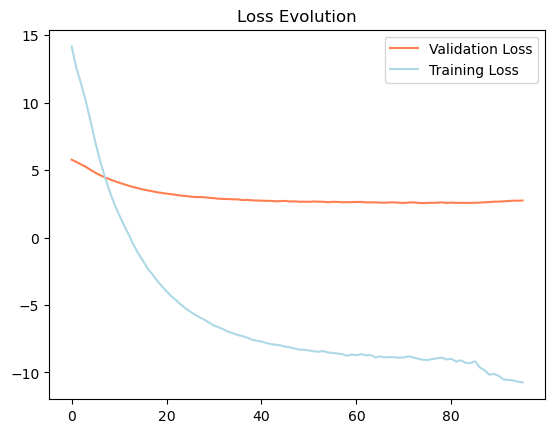

In [26]:
plt.plot(loss_va,color='coral',label='Validation Loss')
plt.plot(loss_tr,color='lightblue',label='Training Loss')
plt.legend()
plt.title('Loss Evolution')
plt.show()

In [27]:
#Create data loaders for prediction with Tpredict length for the future features
# Create instances of the custom dataset for train, validation, and test

train_dataset_fut= zcf.TimeSeriesFuture(train_data, tgt_train_data, TIN, MIN, T, K, Tpredict, time_features=tim_train )
val_dataset_fut = zcf.TimeSeriesFuture(val_data, tgt_val_data, TIN, MIN, T, K, Tpredict, time_features=tim_val )
test_dataset_fut = zcf.TimeSeriesFuture(test_data, tgt_test_data,TIN, MIN, T, K, Tpredict, time_features=tim_test )

# Create data loaders for train, validation, and test sets
train_dataloader_fut = DataLoader(train_dataset_fut,  batch_size=batch_size)
val_dataloader_fut = DataLoader(val_dataset_fut, batch_size=batch_size)
test_dataloader_fut = DataLoader(test_dataset_fut,batch_size=batch_size)

In [28]:
#Creates Plots
model.to(device)
model.load_state_dict(torch.load(file))

out_test = mtr.predict( model, test_dataloader_fut,Tpredict, device=device,inference=None,show_progress=False).cpu().mean(axis=1)
out_val = mtr.predict( model, val_dataloader_fut,Tpredict,device=device,inference=None,show_progress=False).cpu().mean(axis=1)
out_train = mtr.predict( model, train_dataloader_fut,Tpredict,device=device,inference=None,show_progress=False).cpu().mean(axis=1)

if comp_diff:
    out_train = zai.cumsum_with_init(out_train, trIC.cpu())
    out_val = zai.cumsum_with_init(out_val, vaIC.cpu())
    out_test = zai.cumsum_with_init(out_test, teIC.cpu())

out_test = out_test.cpu().detach().numpy()
out_val = out_val.cpu().detach().numpy()
out_train = out_train.cpu().detach().numpy()

In [29]:
# a,b,c,d = next(iter(test_dataloader))
# len(test_dataset)


In [30]:
# for a,b,c,d in test_dataloader:
#    print(a.shape)


# testembed = zaic.FixedPositionalEmbedding(configuration.input_seq, configuration.input_size, 64).to(device)

# testembed(a)

In [31]:
indt2m= PDX[plfield]['index']
out_train_tot, out_val_tot, out_test_tot, true_tot = \
           zai.rescale(params,PDX, out_train, out_val, out_test)
            # zai.rescale(params,PDX, out_train[:,:,indt2m], out_val[:,:,indt2m], out_test[:,:,indt2m])



out_test_p = out_test_tot[...,indt2m] 
out_train_p = out_train_tot[...,indt2m] 
out_val_p = out_val_tot[...,indt2m] 
truep = true_tot[..., indt2m]


Processing field T that is Source_data
Number of modes retained 14
(994, 14)

Processing field t2m that is Source_data
Number of modes retained 26
(994, 26)
(761, 12, 40)


18 778 808 898 928 982
Initial sequence of 18 months, 
	 the Training   starts at: 	1941-09-01 00:00:00
	Validation starts at: 	2007-07-01 00:00:00
	First Forecast at:	2017-07-01 00:00:00 valid until 	2018-06-01 00:00:00
	Initial Sequence from:	2016-01-01 00:00:00 (910) to	2017-06-01 00:00:00 (927)
	First IC Forecast at:	2017-06-01 00:00:00 valid until 	2018-06-01 00:00:00


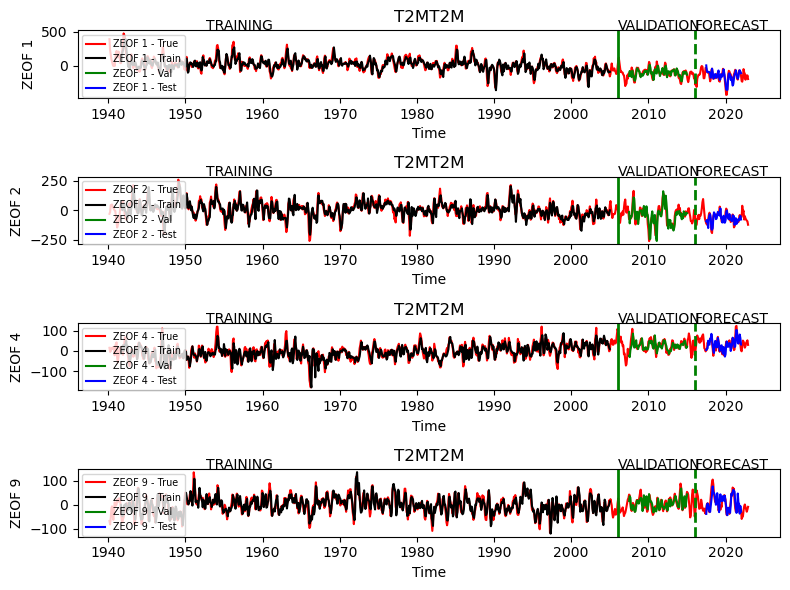

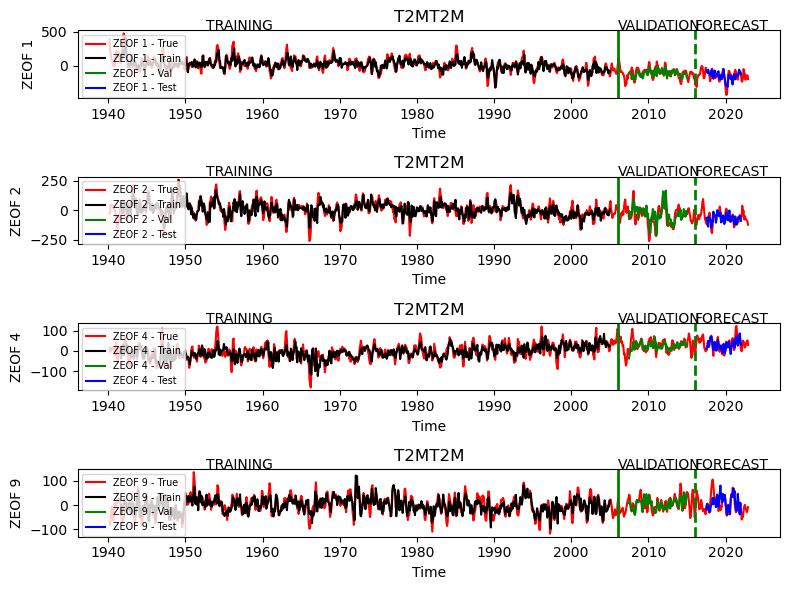

In [32]:


times = data_time
# Plot the first subplot for the month monpred
monpred = 1

starttr = params['train_first_fcs']
endtr = params['train_last_fcs']
startval = params['val_first_fcs']
endval = params['val_last_fcs']
starttest = params['test_first_fcs']
endtest = params['test_last_fcs']
print(starttr,endtr,startval,endval,starttest,endtest)
print(f'Initial sequence of {TIN} months, \n\t the Training   starts at: \t{times[starttr]}')
print(f'\tValidation starts at: \t{times[startval]}')
print(f'\tFirst Forecast at:\t{times[starttest]} valid until \t{times[starttest+Tpredict-1]}')
print(f'\tInitial Sequence from:\t{times[starttest-TIN]} ({starttest-TIN}) to\t{times[starttest-1]} ({starttest-1})')
print(f'\tFirst IC Forecast at:\t{times[starttest-1]} valid until \t{times[starttest-1+Tpredict]}')



tit =Score_Field
def plot_result(ax1,out_train,out_val,out_test,monpred,neof,leof,tit,true=None):
    
    ax1.plot(times,true[:,neof], color='red', label=leof +' - True')
    ax1.plot(times[starttr:endtr+1],out_train[:,monpred,neof], color='black', label=leof +' - Train')
    ax1.plot(times[startval:endval+1],out_val[:,monpred,neof], color='green', label=leof +' - Val')
    ax1.plot(times[starttest:endtest+1],out_test[:,monpred,neof], color='blue', label=leof +' - Test')
    # ax1.set_xlim(times[1500],times[1600])
    ax1.set_xlabel('Time')
    ax1.set_ylabel(leof)
    ax1.set_title(tit)
    ax1.axvline(times[train_size],color='green',lw=2.0)
    ax1.axvline(times[train_size+val_size],color='green',lw=2.0,linestyle='dashed')
    _, yt = ax1.get_ylim()
    ax1.text(times[150],yt+1,'TRAINING')
    ax1.text(times[train_size],yt+1,'VALIDATION')
    ax1.text(times[train_size+val_size],yt+1,'FORECAST')
    # ax1.set_xlim((times[1500],times[1600]))
    ax1.legend(loc='upper left',fontsize='x-small')
    return None
# Create a figure with two subplots
# fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6))

# plot_result(ax1,out_train_S,out_val_S,out_test_S,monpred,0,'EOF 1',tit)
# plot_result(ax2,out_train_S,out_val_S,out_test_S,monpred,1,'EOF 2',tit)

# Adjust the layout to avoid overlapping labels and titles
# plt.tight_layout()

# Display the figure
# plt.show()

# Create a figure with two subplots

titz = tit
for Tp in range(2):
    fig, (ax1, ax2,ax3,ax4) = plt.subplots(4, 1, figsize=(8, 6))
    plot_result(ax1,out_train_p,out_val_p,out_test_p,Tp,0,'ZEOF 1',titz,true=truep)
    plot_result(ax2,out_train_p,out_val_p,out_test_p,Tp,1,'ZEOF 2',titz,true=truep)
    plot_result(ax3,out_train_p,out_val_p,out_test_p,Tp,3,'ZEOF 4',titz,true=truep)
    plot_result(ax4,out_train_p,out_val_p,out_test_p,Tp,4,'ZEOF 9',titz,true=truep)
    # Adjust the layout to avoid overlapping labels and titles
    plt.tight_layout()
    plt.show()


In [33]:
Cont = namedtuple('Contours', 'max min int')
cont_ = Cont(4, -3, 0.5)
cont_

Contours(max=4, min=-3, int=0.5)

In [34]:
# cont = [-3, 3, 0.25]

plfield=Score_Field
arealatz = zai.select_field_key(INX,plfield,'arealat')
arealonz = zai.select_field_key(INX,plfield,'arealon')

#Fix contours for variables
Cont = namedtuple('Contours', 'max min int')
SST_cont = Cont(4, -4, 0.25)
T2M_cont = Cont(6, -6, 0.25)
Z500_cont = Cont(1200, -1200, 100.)   

print(f'Verification done on {plfield}')

Verification done on T2MT2M


In [35]:
startdate = data_time[params['test_first_fcs']-1]
enddate = data_time[params['test_last_fcs']-1]
truncated_verification = INX[plfield]['mr']
F, P, Obs  = zai.eof_to_grid(Score_Field, out_test_p, startdate, enddate, INX=PDX, params=params, truncation=truncated_verification)

Verification using truncated EOFs with 26 modes
Obs from 1940-03-01T00:00:00.000000000 to 2022-12-01T00:00:00.000000000

Number of cases 55
Obs from 2017-06-01 00:00:00 to 2021-12-01 00:00:00

Forecasts for IC at 2017-06-01 00:00:00 to 2021-12-01 00:00:00 and prediction time of 12 months
Forecast shape (55, 13, 45241), 2017-06-01T00:00:00.000000000 to 2021-12-01T00:00:00.000000000
Persistence shape (55, 13, 45241), 2017-06-01T00:00:00.000000000 to 2021-12-01T00:00:00.000000000


In [36]:
Ft = zai.make_fcst_array(startdate,enddate,Tpredict+1,F)
Pt = zai.make_fcst_array(startdate,enddate,Tpredict+1,P)



Number of times 55, number of leads 13, number of features 45241
DatetimeIndex(['2017-06-01', '2017-07-01', '2017-08-01', '2017-09-01',
               '2017-10-01', '2017-11-01', '2017-12-01', '2018-01-01',
               '2018-02-01', '2018-03-01', '2018-04-01', '2018-05-01',
               '2018-06-01', '2018-07-01', '2018-08-01', '2018-09-01',
               '2018-10-01', '2018-11-01', '2018-12-01', '2019-01-01',
               '2019-02-01', '2019-03-01', '2019-04-01', '2019-05-01',
               '2019-06-01', '2019-07-01', '2019-08-01', '2019-09-01',
               '2019-10-01', '2019-11-01', '2019-12-01', '2020-01-01',
               '2020-02-01', '2020-03-01', '2020-04-01', '2020-05-01',
               '2020-06-01', '2020-07-01', '2020-08-01', '2020-09-01',
               '2020-10-01', '2020-11-01', '2020-12-01', '2021-01-01',
               '2021-02-01', '2021-03-01', '2021-04-01', '2021-05-01',
               '2021-06-01', '2021-07-01', '2021-08-01', '2021-09-01',
            

In [37]:
Np,Nl,NumPoints  = Ft.shape
ERROR = 'L2'

corrresult = np.zeros((Tpredict+1,Np))
persistence = np.zeros((Tpredict+1,Np))
rmsres = np.zeros((Tpredict+1,Np))
rmsper = np.zeros((Tpredict+1,Np))

for idx, ic in enumerate(Ft.time):
    ftmp = zai.select_fcst(ic, Ft)
    ptmp = zai.select_fcst(ic, Pt)
    otmp = Obs.sel(time=ftmp.time)
    corrresult[:,idx] = xr.corr(otmp, ftmp, dim='z').data
    persistence[:,idx] = xr.corr(otmp, ptmp, dim='z').data
    if ERROR == 'L1':
        rmsres[:,idx] = np.sum(abs(ftmp - otmp),axis=1).data/NumPoints
        rmsper[:,idx] = np.sum(abs(otmp - ptmp),axis=1).data/NumPoints
    else:
        rmsres[:,idx] = np.sum(abs(ftmp - otmp)**2,axis=1).data/NumPoints
        rmsper[:,idx] = np.sum(abs(otmp - ptmp)**2,axis=1).data/NumPoints
    
    

In [38]:

dyn_cmcc = {'center':'cmcc','system':['3','35'], 'SST':'SST', 'T2M':'2t', 'Z500':'Z500'}

dyn_cases = [dyn_cmcc]

match Score_Field:
    case 'SSTSST':
        ver_f = INX[plfield]['field'].upper()
    case 'T2MT2M':
        ver_f = INX[plfield]['field'].upper()
    case 'Z500':
        ver_f = 'Z500'
        
# ndyn = int(endindex[0]-startindex[0]+1)
ngrid = INX[plfield]['X'].A.shape[0]
dyn_area = INX[plfield]['area']
dynddr =  dspaths.seasonal_dir(ver_f)

filever = f'DYN_{ver_f}_{dyn_area}_{params["TIN"]}.nc'

if verify_dyn:
    Tpredict_dyn = 6
    # DYN = zai.make_dyn_verification(ver_f,INX[plfield]['area'], dyn_cases, dynddr, times, dyn_startdate,dyn_enddate, filever) 
    DYN = zai.make_dyn_verification_new(ver_f, dyn_area, dyn_cases, dynddr, times, filever)
    dyn_startdate = DYN.time[0]
    dyn_enddate = DYN.time[-Tpredict_dyn]
    dyn_cases[0]['dyn_startdate'] = dyn_startdate
    dyn_cases[0]['dyn_enddate'] = dyn_enddate

Verification data loaded from file DYN_T2M_EUROPE_18.nc
Verification data shape (50, 6, 45241), times 2018-11-01T00:00:00.000000000 to 2022-12-01T00:00:00.000000000


In [39]:
# Smooth data
# Put label on the last month of the window
if SMOOTH:
    for i in range(len(DYN.time)):
        DYN[i,:,:] = DYN[i,:,:].rolling(lead=3,center=False,min_periods=3).mean().fillna(0)#dropna(dim='time')

In [40]:
# SHIFT BACKWARRD IC BECAUSE FORECAST ALREADY START AT FIRST FORECSTED MONTH
IC = Obs.sel(time=slice(zai.advance_months(pd.to_datetime(dyn_startdate.data),n=-1),zai.advance_months(pd.to_datetime(dyn_enddate.data),n=-1))).unstack().expand_dims({'lead':[0]},axis=1)
#Align GCM forecasts woth Obs
startdate = pd.to_datetime(IC.time.data)[0]
enddate = pd.to_datetime(IC.time.data)[-1]
print(f'Verified times for IC {startdate}. to {enddate} \n First Forecasts at {dyn_startdate.data} to {dyn_enddate.data}')
# Shift time coordinates so that the initial condition is aligned with first month of GCM
# Forecast
DYN_CUT = DYN.sel(time=slice(zai.advance_months(startdate,n=1),zai.advance_months(enddate,n=1))).assign_coords({"time": IC.time}).unstack()
NEW_DYN = xr.concat([IC,DYN_CUT],dim='lead').stack(z=('lat','lon')).dropna(dim='z')

#Align with Prediction length Tpredict


Verified times for IC 2018-10-01 00:00:00. to 2022-06-01 00:00:00 
 First Forecasts at 2018-11-01T00:00:00.000000000 to 2022-07-01T00:00:00.000000000


In [41]:
NEW_DYN = NEW_DYN.sel(lead=np.arange(min(Tpredict,Tpredict_dyn)+1))

In [42]:
# Optionally truncate also the dynamical forecast to the EOF truncation
NEW_DYN = zai.project_dyn(NEW_DYN, INX, plfield, truncation=truncated_verification)

Tpredict_dyn = len(NEW_DYN.lead)
Dt = zai.make_fcst_array(startdate,enddate,Tpredict_dyn,NEW_DYN)

Verification using truncated EOFs with 26 modes
Number of times 45, number of leads 7, number of features 45241
DatetimeIndex(['2018-10-01', '2018-11-01', '2018-12-01', '2019-01-01',
               '2019-02-01', '2019-03-01', '2019-04-01', '2019-05-01',
               '2019-06-01', '2019-07-01', '2019-08-01', '2019-09-01',
               '2019-10-01', '2019-11-01', '2019-12-01', '2020-01-01',
               '2020-02-01', '2020-03-01', '2020-04-01', '2020-05-01',
               '2020-06-01', '2020-07-01', '2020-08-01', '2020-09-01',
               '2020-10-01', '2020-11-01', '2020-12-01', '2021-01-01',
               '2021-02-01', '2021-03-01', '2021-04-01', '2021-05-01',
               '2021-06-01', '2021-07-01', '2021-08-01', '2021-09-01',
               '2021-10-01', '2021-11-01', '2021-12-01', '2022-01-01',
               '2022-02-01', '2022-03-01', '2022-04-01', '2022-05-01',
               '2022-06-01'],
              dtype='datetime64[ns]', freq='MS')


In [43]:
if write_result:
    # Write forecast and verification
    case_data =  xr.Dataset({'F': F,'V': V,'P':P, 'SD':SD,'VD':VD})
    filedyn = f"RES_{params['savefile']}.nc"

    import cf_xarray as cfxr
    xr.set_options(keep_attrs=True)
    cfxr.encode_multi_index_as_compress(case_data, 'z').to_netcdf(filedyn)

In [44]:
match Score_Field:
    case 'SSTSST':
        cont_ = SST_cont
    case 'T2MT2M':
        cont_ = T2M_cont
    case 'Z500':
        cont_ = Z500_cont


np.arange(cont_.min,cont_.max,cont_.int)
cont=[cont_.min, cont_.max, cont_.int]

# utp.many_plots(  Obs,  Score_Field, Score_Field, cont, '2020-05-01', world_projection='Pacific', colorbars=False,
#                suptitle='Obs', mainlabel='', mode='time', lead=0, ncols=2, nrows=3, arealatz=arealatz, arealonz=arealonz, centlon=180,labfile=None)


In [45]:
np.arange(cont_.min,cont_.max,cont_.int)
cont=[cont_.min, cont_.max, cont_.int]

# cont = []
# if Tpredict > 1:
#     ftmp = zai.select_fcst('2020-08-01', Ft)
#     vtmp = Obs.sel(time=ftmp.time)
#     utp.Forecast_plots(ftmp, vtmp,  Score_Field, None, cont,  pictimes=[1,2,3], title='ClimFormer Verification', \
#                                   world_projection='Pacific', colorbars=False, mainlabel='', arealatz=arealatz, arealonz=arealonz, centlon=PDX[plfield]['centlon'],labfile=None)


In [46]:
dtmp = zai.select_fcst('2020-08-01', Dt)
vtmp = Obs.sel(time=dtmp.time)

# utp.Forecast_plots(dtmp, vtmp,  Score_Field, None, cont,  pictimes=[1,2,3], title='GCM Verification', \
#                               world_projection='Pacific', colorbars=False, mainlabel='', arealatz=arealatz, arealonz=arealonz, centlon=PDX[plfield]['centlon'],labfile=None)


In [47]:
if verify_dyn:
    ERROR = 'L2'
    Tpredict_dyn = len(NEW_DYN.lead)

    # The number of forecast for the dynamical list is limited to 7 months, so the number of cases must be reduced.
    number_of_dyn = len(NEW_DYN.time)

    corrdyn = np.zeros((Tpredict_dyn,number_of_dyn))
    rmsdyn = np.zeros((Tpredict_dyn,number_of_dyn))
    # Dt = zai.make_fcst_array(startdate,enddate,Tpredict_dyn,NEW_DYN)
    NumPoints = len(Dt.z)
    for idx, ic in enumerate(Dt.time):
       
        ftmp = zai.select_fcst(ic, Dt)
        otmp = Obs.sel(time=ftmp.time)

        #Stack and unstack to align arrays
        ftmp1 = ftmp.unstack().stack(z=('lat','lon'))
        otmp1 = otmp.unstack().stack(z=('lat','lon'))
        # corrdyn[:,idx] = zai.align_and_compute_correlation(otmp1, ftmp1, dim='z').data
        corrdyn[:,idx] = xr.corr(otmp1, ftmp1, dim='z').data
        
        
        if ERROR == 'L1':
                rmsdyn[:,idx]= np.sum(abs(ftmp1-otmp1),axis=1).data/NumPoints
        else:
                rmsdyn[:,idx]= np.sum(abs(ftmp1-otmp1)**2,axis=1).data/NumPoints

    if SMOOTH:
        rmsdyn[0:3,:] = np.nan

In [48]:
Dtc = Dt.sel(time=slice(Dt.time[0],Ft.time[-1]))
Ptc = Pt.sel(time=slice(Dt.time[0],Ft.time[-1]))
Ftc= Ft.sel(time=slice(Dt.time[0],Ft.time[-1]))

In [49]:
# from AIModels.obs_lead_constructor import construct_obs_leads

# obs shape: (100, 1000) - 100 time steps, 1000 grid points
obs_leads = val.construct_obs_leads(Obs.unstack(), n_leads=7, ic0=Dt.time[0].data,n_init_conditions=39)
# Ds Forecasts
mobs_leads = val.construct_obs_leads(Obs.unstack(), n_leads=13, ic0=Ft.time[0].data,n_init_conditions=39)


In [50]:
DDt= Dtc.unstack().stack(z=('lat','lon'))
DObs = obs_leads.stack(z=('lat','lon'))
DPt = Ptc.sel(time=Dtc.time,lead=slice(0,6)).unstack().stack(z=('lat','lon'))

In [51]:
# Eliminate small differencesa in IC
DDt[:,0,:] = DObs[:,0,:]

# Now compute RPSS

In [52]:
# Compute RPSS for dynamical forecasts
rpss_results_dyn = val.compute_rpss_dyn(DDt, DObs,DPt, verbose=True, device=device,leave_one_out=True)

Lead 00: RPSS(area)= 1.0000 | BSS(area) p1= 1.0000, p2= 1.0000, p3= 1.0000
Lead 01: RPSS(area)=-1.2501 | BSS(area) p1=-1.8332, p2= 0.0714, p3=-0.6185
Lead 02: RPSS(area)=-0.4259 | BSS(area) p1=-0.8118, p2= 0.2230, p3=-0.0157
Lead 03: RPSS(area)= 0.1214 | BSS(area) p1= 0.0033, p2= 0.1052, p3= 0.2450
Lead 04: RPSS(area)= 0.1026 | BSS(area) p1=-0.0662, p2= 0.0934, p3= 0.2760
Lead 05: RPSS(area)= 0.1282 | BSS(area) p1=-0.0717, p2= 0.1044, p3= 0.3228
Lead 06: RPSS(area)= 0.1235 | BSS(area) p1=-0.0627, p2= 0.1058, p3= 0.3020


In [53]:
# Compute RPSS using the refactored function from RPSS module
MObs = mobs_leads.stack(z=('lat','lon'))
rpss_results = val.compute_rpss_by_lead(Ftc.unstack().stack(z=('lat','lon')), Ptc.unstack().stack(z=('lat','lon')), MObs, verbose=True,device=device,leave_one_out=True)


Lead 00: RPSS(area)= 1.0000 | BSS(area) p1= 1.0000, p2= 1.0000, p3= 1.0000
Lead 01: RPSS(area)= 0.6564 | BSS(area) p1= 0.6620, p2= 0.3741, p3= 0.6508
Lead 02: RPSS(area)= 0.4675 | BSS(area) p1= 0.4632, p2= 0.1557, p3= 0.4718
Lead 03: RPSS(area)= 0.3665 | BSS(area) p1= 0.3664, p2= 0.0619, p3= 0.3666
Lead 04: RPSS(area)= 0.3506 | BSS(area) p1= 0.3456, p2=-0.0306, p3= 0.3557
Lead 05: RPSS(area)= 0.3024 | BSS(area) p1= 0.3205, p2=-0.0732, p3= 0.2838
Lead 06: RPSS(area)= 0.2868 | BSS(area) p1= 0.2981, p2=-0.0985, p3= 0.2755
Lead 07: RPSS(area)= 0.2628 | BSS(area) p1= 0.2688, p2=-0.0275, p3= 0.2570
Lead 08: RPSS(area)= 0.2559 | BSS(area) p1= 0.2585, p2=-0.0395, p3= 0.2535
Lead 09: RPSS(area)= 0.2663 | BSS(area) p1= 0.2765, p2=-0.0707, p3= 0.2564
Lead 10: RPSS(area)= 0.2862 | BSS(area) p1= 0.2800, p2=-0.0958, p3= 0.2919
Lead 11: RPSS(area)= 0.3100 | BSS(area) p1= 0.2923, p2=-0.1013, p3= 0.3266
Lead 12: RPSS(area)= 0.2934 | BSS(area) p1= 0.2996, p2=-0.0814, p3= 0.2875


In [54]:
valfile = f'./testval_{case}.csv'
val.save_rpss_to_csv(rpss_results, valfile)
valfile1 = f'./dynval_{case}.csv'
val.save_rpss_to_csv(rpss_results_dyn, valfile1)


In [55]:
Titolo = namedtuple('Titolo', 'maintitle lefttitle righttitle')
a = Titolo('SST','Exp1','EOF1')
a.maintitle

'SST'

In [56]:
params.keys()

dict_keys(['TIN', 'MIN', 'T', 'K', 'EPOCHS', 'RESTART', 'D_DIM', 'Tpredict', 'FFN_DIM', 'ENC_Heads', 'DEC_Heads', 'enc_dec_layers', 'scaling', 'LR', 'WD', 'savefile', 'discount', 'lags', 't_type', 'device', 'start_date', 'end_training', 'start_val', 'end_val', 'test_start', 'test_end', 'train_period_start', 'train_period_end', 'val_period_start', 'val_period_end', 'test_period_start', 'test_period_end', 'train_first_fcs', 'train_last_fcs', 'val_first_fcs', 'val_last_fcs', 'test_first_fcs', 'test_last_fcs'])

In [57]:
#Add to configuration case the Model configuration
caseid =  {'case':case, 'version':'V5', 'SMOOTH':SMOOTH, 'normalization':normalization,\
           'only_valtrain_eof':only_valtrain_eof, 'eof_interval':eof_interval,\
           'shift':shift,'period':period, 'InputVars':InputVars,'PredictVars':PredictVars}

plfield = Score_Field
starttest = params['test_period_start']  + TIN
endtest = starttest + Np - 1

figarea = INX[plfield]['area']
figinfield = [i for i in INX.keys()]
idfig = f"FIELDS={figinfield}, MIN={MIN},MOUT={K},in={TIN},FD={params['FFN_DIM']},H={params['ENC_Heads']},LY={params['enc_dec_layers']}"

data_dict = {}
# Store the other variables in the dictionary
data_dict = {"description": case, "subcase_var":subcase_var, "subcase":subcase,"dataversion": caseid['version'], "invar_dict":invar_dict, "pred_dict":pred_dict,
             "author": "AN", "date": today_date, "name": idfig, 'config':configuration, 'area':figarea,
             "size_model":zai.count_parameters(model), "best_val_loss":best_val_loss,"model_config":configuration,"params":params,
             "verification_field":plfield, "input_fields":list(INX.keys()),"output_fields":list(PDX.keys()),'eof':str([i.mr for i in InputVars]),
             'GCMcorr':corrdyn, "corr":corrresult, "pers":persistence,
             "GCMrms":rmsdyn, "rms":rmsres, "rmsper":rmsper}
fileout=f'{case}_V{subcase_var}_{subcase}_corr_data'
# Save the dictionary to a file using pickle
with open(fileout, "wb") as f:
    pickle.dump(data_dict, f)

Writing data to ACC_Score_Y621s_299_1_mean.csv
['299', '1', "['T850', 'T2M']", '[1, 2, 3, 4]', '256', '1', '[0.95, 0.95]', '1.0', '18', 'EUROPE']
['Subcase_var', 'Subcase', 'VARS', 'LAGS', 'HID', 'LAYERS', 'EOF', 'DISCOUNT', 'INSEQ', 'AREA']
Writing data to RMS_Score_Y621s_299_1_mean.csv
['299', '1', "['T850', 'T2M']", '[1, 2, 3, 4]', '256', '1', '[0.95, 0.95]', '1.0', '18', 'EUROPE']
['Subcase_var', 'Subcase', 'VARS', 'LAGS', 'HID', 'LAYERS', 'EOF', 'DISCOUNT', 'INSEQ', 'AREA']


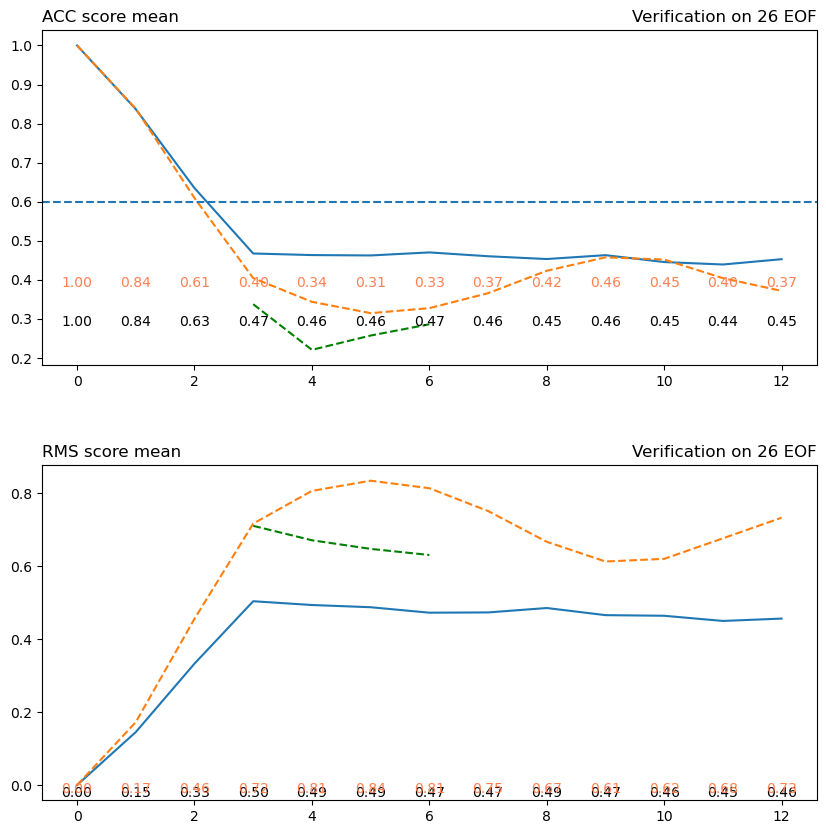

In [58]:
if truncated_verification is None:
    labtit = 'Total verification'
else:
    labtit = f'Verification on {truncated_verification} EOF'
labscore = f'ACC_Score_{case}_{subcase_var}_{subcase}'
utp.plot_skill(corrresult,persistence,rmsres,rmsper,rmsdyn=rmsdyn,corrdyn=corrdyn,skill='mean',numbers=True,printout=True, data_dict=data_dict,
               savefig=False, labtit=labtit,labfile=labscore)

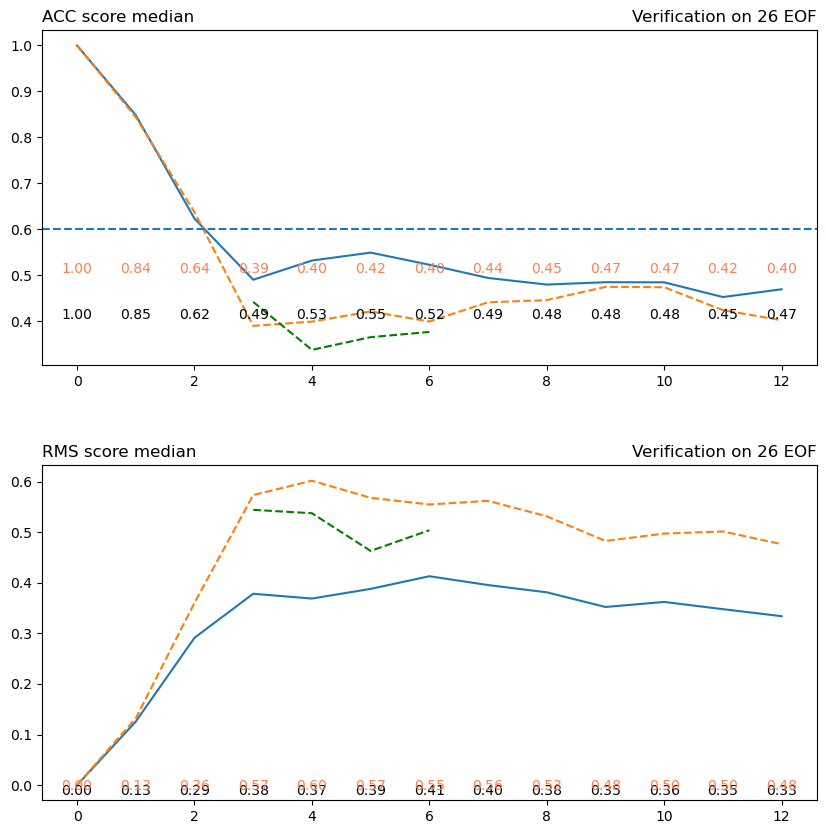

In [59]:
utp.plot_skill(corrresult,persistence,rmsres,rmsper,rmsdyn=rmsdyn,corrdyn=corrdyn,skill='median',numbers=True, printout=False, labtit=labtit,labfile=None)
    

In [60]:
skill = 'median' #'mean'

# Figure for paper

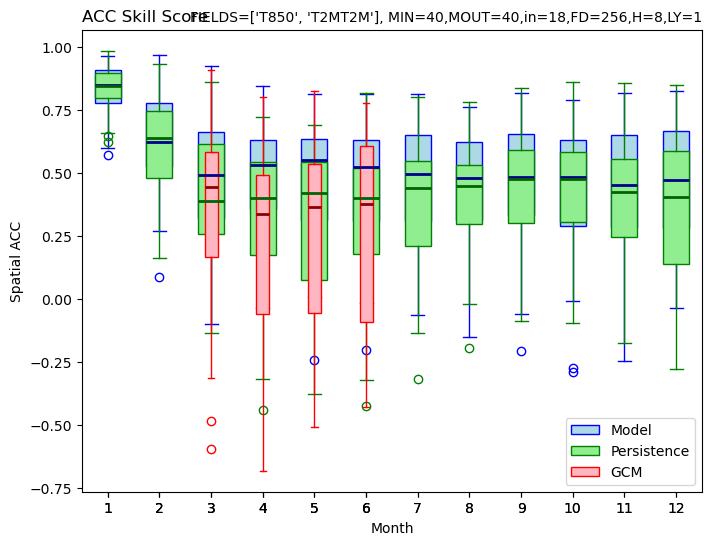

In [61]:
import matplotlib.pyplot as plt
import numpy as np

# Generate some example data
np.random.seed(10)
data = [np.random.normal(0, std, 100) for std in range(1, 4)]

# Create a box plot with customization
plt.figure(figsize=(8, 6))
# box = plt.boxplot(corrresult.T, vert=True, patch_artist=True, notch=False, widths=0.2)
# box1 = plt.boxplot(persistence.T, vert=True, patch_artist=True, notch=False, widths=0.2)

#Customizing box plot appearance

# Create a box plot with different colors for each dataset
box1 = plt.boxplot(corrresult[1:,:].T, patch_artist=True,
                  boxprops=dict(facecolor='lightblue', color='blue'),
                  medianprops=dict(color='darkblue',linewidth=2),
                  whiskerprops=dict(color='blue'),
                  capprops=dict(color='blue'),
                  flierprops=dict(markeredgecolor='blue'),
                  )
box2 = plt.boxplot(persistence[1:,:].T, patch_artist=True,
                  boxprops=dict(facecolor='lightgreen', color='green'),
                  medianprops=dict(color='darkgreen',linewidth=2),
                  whiskerprops=dict(color='green'),
                  capprops=dict(color='green'),
                  flierprops=dict(markeredgecolor='green'),
                  )


if verify_dyn:
    box3 = plt.boxplot(corrdyn[1:,:].T, patch_artist=True, widths=0.25,
                  boxprops=dict(facecolor='lightpink', color='red'),
                  medianprops=dict(color='darkred',linewidth=2),
                  whiskerprops=dict(color='red'),
                  capprops=dict(color='red'),
                  flierprops=dict(markeredgecolor='red'),
                  )

# Add a legend
plt.legend([box1["boxes"][0], box2["boxes"][0],box3["boxes"][0]], ['Model', 'Persistence','GCM'], loc='best')

# Add title and labels
plt.title('ACC Skill Score',loc='left')
plt.title(idfig,loc='right',fontsize=10)
plt.xlabel('Month')
plt.ylabel('Spatial ACC')

# Show the plot
# plt.savefig(f'FIG_{file}_Box.pdf')
plt.show()

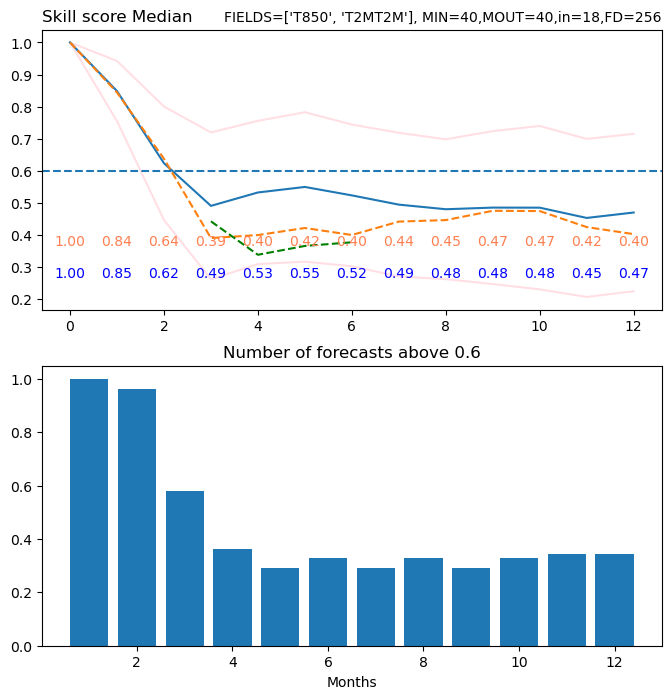

In [62]:


fig, (ax2, ax3) = plt.subplots(2, 1, figsize=(8, 8))

# for i in range(1,Tpredict,5):
#     hl,=ax1.plot(times[starttest:endtest+1],corrresult[i,:],label=f'Month {i}')
#     ax1.plot(times[starttest:endtest+1],persistence[i,:],label=f'Month {i}',color=hl.get_color(), linestyle='dashed')
idfig = f"FIELDS={figinfield}, MIN={MIN},MOUT={K},in={TIN},FD={params['FFN_DIM']}"
    
# ax1.set_ylim(-0.4,1.2)
# ax1.set_title('Skill Score Median',loc='left')
# ax1.set_title(idfig,loc='right',fontsize=10)
# ax1.legend()
skill='median'

tim = np.arange(0,Tpredict+1)

match skill:
    case 'mean':
        sk = np.mean(corrresult,axis=1)
        ps = np.mean(persistence,axis=1)
        if verify_dyn:
            dyn = np.mean(corrdyn,axis=1)  # Start from month 1
        ax2.plot(tim,corrresult.mean(axis=1)+corrresult.std(axis=1),color='pink',alpha=0.5)
        ax2.plot(tim,corrresult.mean(axis=1)-corrresult.std(axis=1),color='pink',alpha=0.5)
    case 'median':
        sk = np.median(corrresult,axis=1)
        ps = np.median(persistence,axis=1)
        if verify_dyn:
            dyn = np.median(corrdyn,axis=1)  # Start from month 1
        ax2.plot(tim,np.median(corrresult,axis=1)+corrresult.std(axis=1),color='pink',alpha=0.5)
        ax2.plot(tim,np.median(corrresult,axis=1)-corrresult.std(axis=1),color='pink',alpha=0.5)
    case _:
        raise ValueError('Invalid skill choice')
ax2.plot(tim,sk)
ax2.plot(tim,ps,linestyle='dashed')
if verify_dyn:
    ax2.plot(tim[0:7],dyn,linestyle='dashed',color='green')
        
ax2.axhline(0.6,linestyle='dashed')
ax2.set_title('Skill score Median',loc='left')
ax2.set_title(idfig,loc='right',fontsize=10)
for ii in range(0,Tpredict+1):
    ax2.text(ii,min(ax2.get_ylim())+0.1,f'{sk[ii]:4.2f}',horizontalalignment='center',color='blue')
    ax2.text(ii,min(ax2.get_ylim())+0.2,f'{ps[ii]:4.2f}',horizontalalignment='center',color='coral')
    
tw = [sum(np.where(corrresult[i,:] > 0.6, 1,0))/Np for i in range(Tpredict)]
ax3.bar(np.arange(1,Tpredict+1),tw)
ax3.set_title('Number of forecasts above 0.6')
ax3.set_xlabel('Months')
# plt.savefig(f'FIG_{file}_{skill}.pdf')
plt.show()

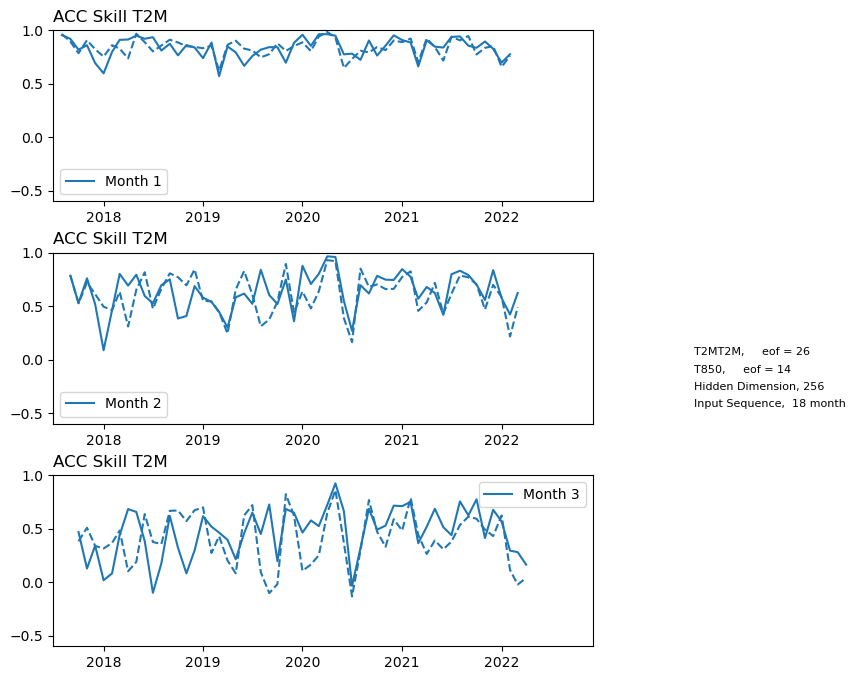

In [63]:
#Figure for forecast

# Create a figure with GridSpec layout
fig = plt.figure(figsize=(10, 8))
gs = fig.add_gridspec(3, 2, width_ratios=[4, 1], height_ratios=[1, 1, 1], wspace=0.3, hspace=0.3)

# Left panels
ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[1, 0])
ax3 = fig.add_subplot(gs[2, 0])

# Right panel, aligned with the middle left panel
ax4 = fig.add_subplot(gs[1, 1])

tit = f'ACC Skill {plfield[0:3]}'
if_time = [1]
col = ['black','red','lightblue', 'blue','green']

# GCM Dates
date_range = pd.date_range(start='2019-01-01', end='2022-05-01',freq='M')
gcm_index_start = times.get_loc('2019-01-01')
gcm_index_end = times.get_loc('2022-06-01')

for i in if_time:
    hl,=ax1.plot(times[starttest+i:endtest+1+i],corrresult[i,:],label=f'Month {i}')
    ax1.plot(times[starttest+i:endtest+1+i],persistence[i,:],color=hl.get_color(), linestyle='dashed')
    # ax1.plot(times[gcm_index_start+i:gcm_index_end+1+i],corrdyn[i,:],color='green', linestyle='dashed')

ax1.set_xlim(times[starttest], times[endtest+Tpredict-1])
ax1.set_ylim(-0.6,1.0)
ax1.set_title(tit,loc='left')
# ax1.set_title(idfig,loc='right',fontsize=10)
ax1.legend()

if_time = [2]
for i in if_time:
    hl,=ax2.plot(times[starttest+i:endtest+1+i],corrresult[i,:],label=f'Month {i}')
    ax2.plot(times[starttest+i:endtest+1+i],persistence[i,:],color=hl.get_color(), linestyle='dashed')

ax2.set_xlim(times[starttest], times[endtest+Tpredict-1])
ax2.set_ylim(-0.6,1.0)
ax2.set_title(tit,loc='left')
# ax2.set_title(idfig,loc='right',fontsize=10)
ax2.legend()

if_time = [3]
for i in if_time:
    hl,=ax3.plot(times[starttest+i:endtest+1+i],corrresult[i,:],label=f'Month {i}')
    ax3.plot(times[starttest+i:endtest+1+i],persistence[i,:],color=hl.get_color(), linestyle='dashed')

ax3.set_xlim(times[starttest], times[endtest+Tpredict-1])
ax3.set_ylim(-0.6,1.0)
ax3.set_title(tit,loc='left')
# ax3.set_title(idfig,loc='right',fontsize=10)
ax3.legend()

# Remove the axis and labels for ax4
ax4.axis('off')  # This removes the axis lines and ticks
ax4.set_xticklabels([])  # This removes the x-axis labels
ax4.set_yticklabels([])  # This removes the y-axis labels

# Label the experiment
dfig = f"Predictors={figinfield}, MIN={MIN},MOUT={K},in={TIN},FD={params['FFN_DIM']},H={params['ENC_Heads']},LY={params['enc_dec_layers']}"
delta = 0.0
ffcol = {'fontsize':8, 'color':'black'}

ax4.text(0, 0.1, f'Input Sequence,  {TIN} month', **ffcol) 
ax4.text(0, 0.2, f"Hidden Dimension, {params['FFN_DIM']}", **ffcol) 
for ff in INX.keys():
    lab = f"{ff},     eof = {INX[ff]['mr']}"
    ax4.text(0, 0.3+delta, lab, **ffcol) 
    delta += 0.1
    
    
# Adjust layout
plt.tight_layout()
# plt.savefig(f'FIG_{file}_Month.pdf')
plt.show()

In [64]:

cday = 4
im = np.argmin(corrresult[cday,:])
print(im, corrresult[cday,im])

# Cont = namedtuple('Contours', 'max min int')
# cont_ = Cont(2, -2, 0.25)
np.arange(cont_.min,cont_.max,cont_.int)
cont=[cont_.min, cont_.max, cont_.int]
this_forecast = str(Ft.time.isel(time=im).data[()]).split('T')[0]
# cont = []

ftmp = zai.select_fcst(this_forecast, Ft)
# dtmp = zai.select_fcst(this_forecast, Dt)
vtmp = Obs.sel(time=ftmp.time)
if np.datetime64(this_forecast)  in Dt.time.values:
    print('caz')

8 -0.03441985101468864


 Opening figure , 2 rows and 3 cols 

Setting Fixed Contours
 Contouring from  -1   to 1  with interval   0.1
Setting Fixed Contours
 Contouring from  -1   to 1  with interval   0.1
Setting Fixed Contours
 Contouring from  -1   to 1  with interval   0.1
Setting Fixed Contours
 Contouring from  -1   to 1  with interval   0.1
Setting Fixed Contours
 Contouring from  -1   to 1  with interval   0.1
Setting Fixed Contours
 Contouring from  -1   to 1  with interval   0.1
Setting Fixed Contours
 Contouring from  -1   to 1  with interval   0.1
Setting Fixed Contours
 Contouring from  -1   to 1  with interval   0.1
Setting Fixed Contours
 Contouring from  -1   to 1  with interval   0.1
Setting Fixed Contours
 Contouring from  -1   to 1  with interval   0.1


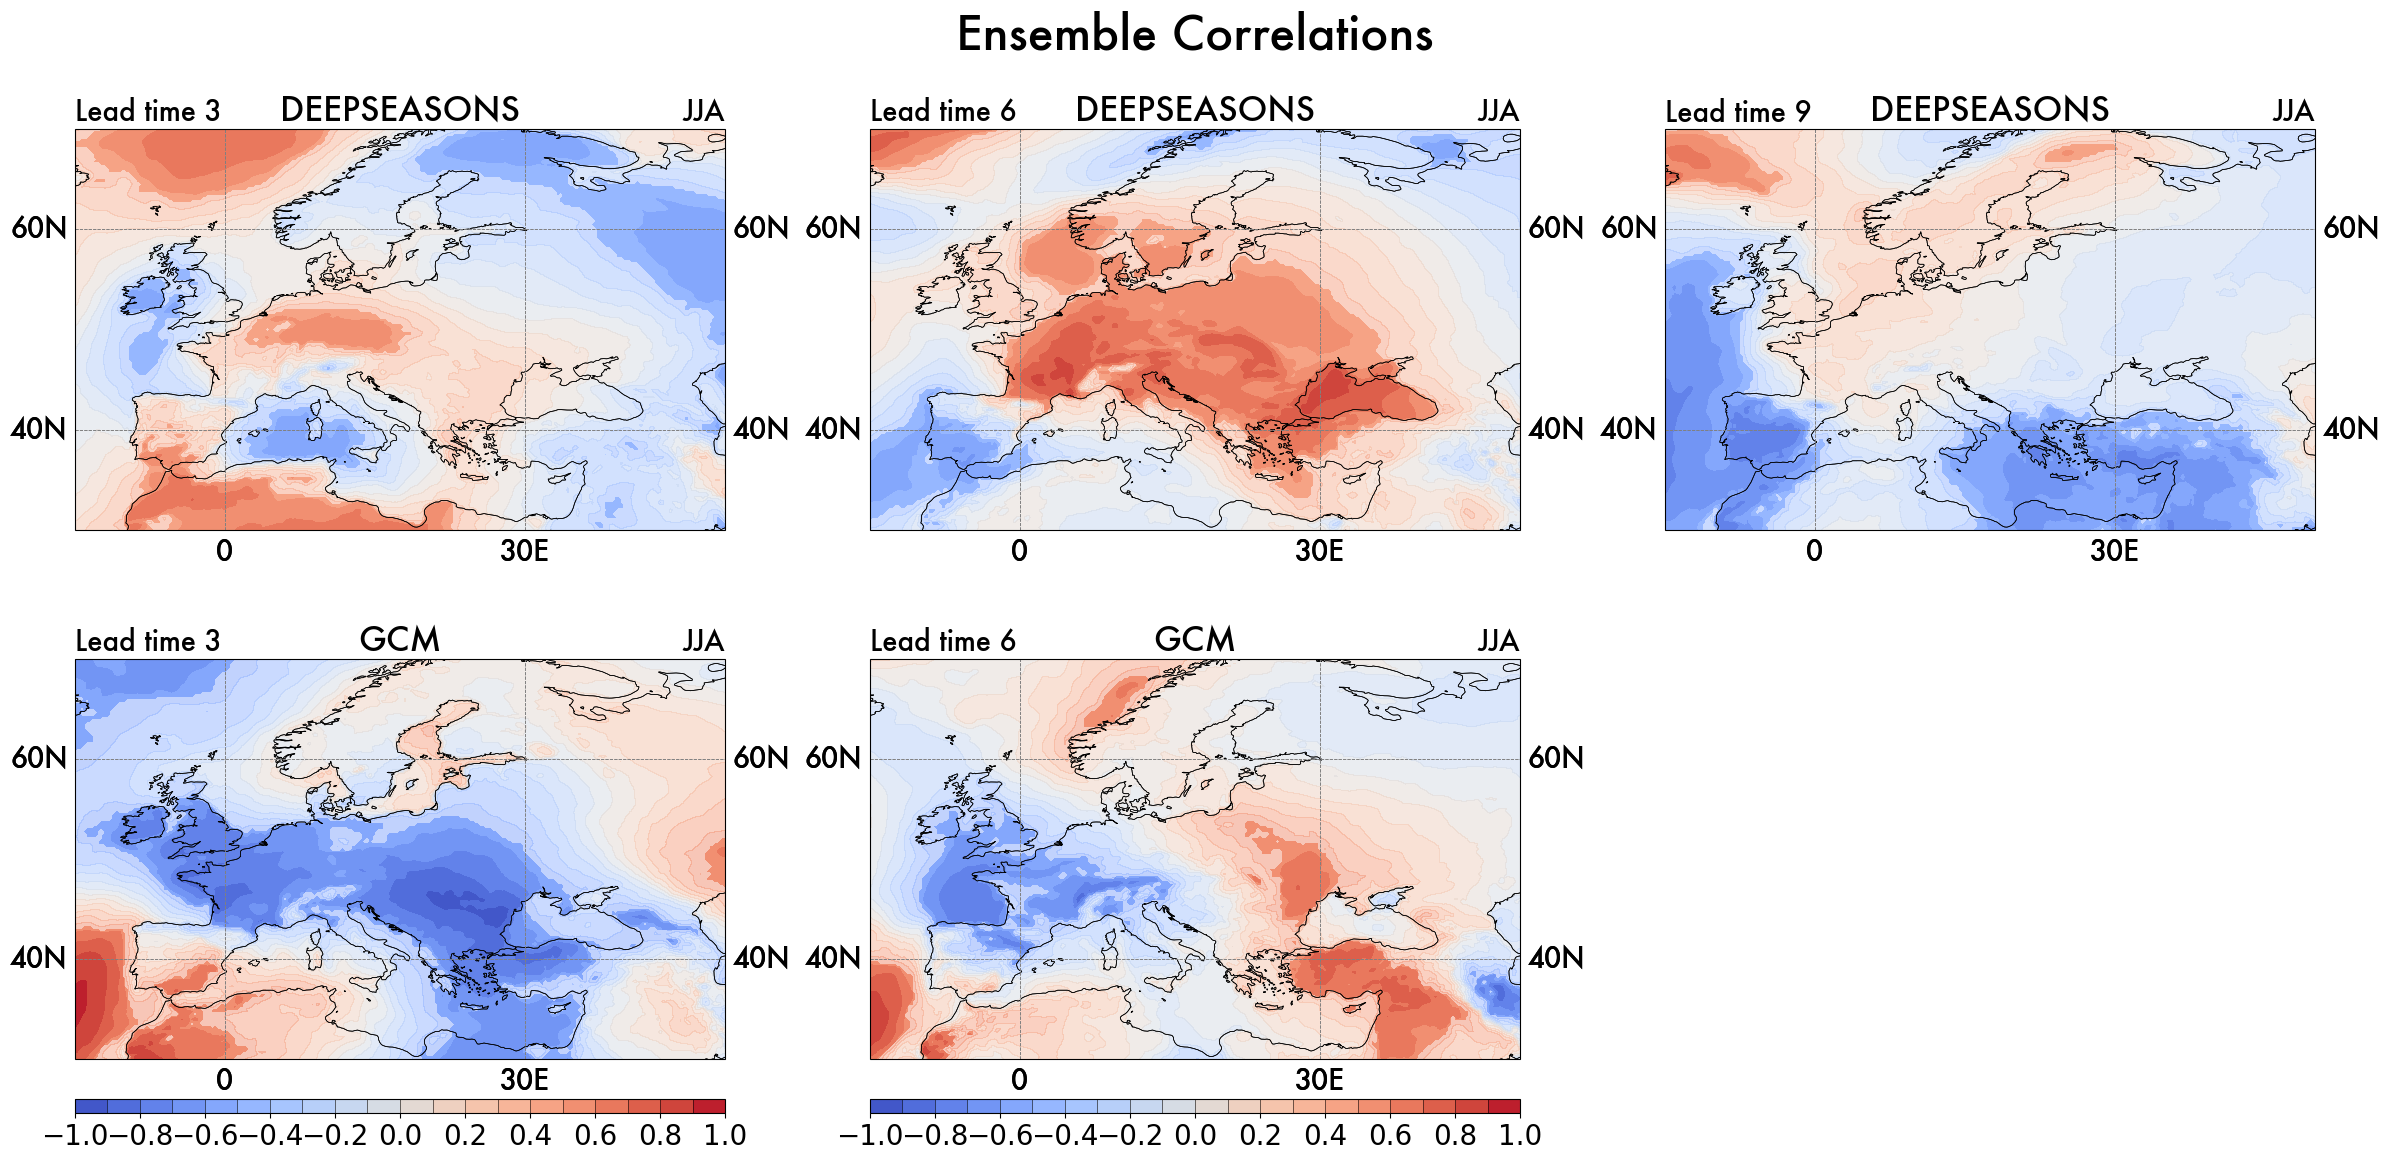

In [65]:
#Plot time correlation
Nplfield = INX[plfield]['mr']

nameeof = zai.select_field_key(INX,plfield,'field')
arealat = zai.select_field_key(INX,plfield,'arealat')

plpro = 'Pacific'
if INX[plfield]['area'] == 'EUROPE':
    plpro = 'Atlantic'
slim=4.0
cont1=[-slim,slim,0.5]
cont2=[-slim,slim,0.5]
cont1=[-1,1,0.1]
cont2=cont1
monlab = 'JJA'
# monlab= [12,1,2]

fig,axu,pro=zmap.init_figure(2,3,plpro, constrained_layout=False, figsize=(24,12) )

if_time = [3,6,9]

for ind, this in enumerate(if_time):
    label1 = f'{monlab}'
    index = utp.select_months(Ft.time, monlab)
    Zt = Ft.isel(time=index).sel(lead=this).assign_coords(time=Ft.isel(time=index).sel(lead=this).valid_time)
    PZt = Pt.isel(time=index).sel(lead=this).assign_coords(time=Pt.isel(time=index).sel(lead=this).valid_time)
    if this < 7:
        indexd = utp.select_months(Dt.time, monlab)
        DZt = Dt.isel(time=indexd).sel(lead=this).assign_coords(time=Pt.isel(time=indexd).sel(lead=this).valid_time)
        DVt = Obs.sel(time=DZt.time) 
    Vt = Obs.sel(time=Zt.time)    
    
    xcc0=xr.corr(Zt, Vt, dim='time')
    xcc1=xr.corr(DZt, DVt, dim='time')
    sig0, _ = utp.calculate_significance(xcc0,len(Zt.time),alpha=0.1,two_tailed=True)
    sig1, _ = utp.calculate_significance(xcc1,len(DVt.time),alpha=0.1,two_tailed=True)
    
    handle=zmap.xmap(xcc0.unstack(),cont1, pro, ax=axu[0,ind],refline=None, c_format='{:4.2f}',data_cent_lon=INX[plfield]['centlon'],latlabel=[60,40],\
                           xlimit=(arealon[0],arealon[1]), ylimit=(arealat[1],arealat[0]), title_style={ "fontsize": 24}, label_style={ "fontsize": 20},
                     title={'maintitle':'DEEPSEASONS', 'lefttitle':f'Lead time {this}','righttitle':label1},cmap='coolwarm',contour=False)
  
    handle['filled'].set_alpha(0.5)
    handle2=zmap.xmap(sig0.unstack(),cont1, pro, ax=axu[0,ind],refline=None, c_format='{:4.2f}',data_cent_lon=INX[plfield]['centlon'],latlabel=[60,40],\
                           xlimit=(arealon[0],arealon[1]), ylimit=(arealat[1],arealat[0]), title_style={ "fontsize": 24}, label_style={ "fontsize": 20},
                     title={'maintitle':'DEEPSEASONS', 'lefttitle':f'Lead time {this}','righttitle':label1},cmap='coolwarm',contour=False)
  
    # zmap.add_colorbar(fig, handle['filled'], axu[0,ind], label_size=8,edges=True)
    # ax[1].projection = zmap.choose_projection('Atlantic')
    if this < 7:
        han1=zmap.xmap(xcc1.unstack(), cont2, plpro, ax=axu[1,ind], refline=None,c_format='{:4.2f}',data_cent_lon=INX[plfield]['centlon'],latlabel=[60,40],\
                           xlimit=(arealon[0],arealon[1]),ylimit=(arealat[1],arealat[0]),title_style={ "fontsize": 24}, label_style={ "fontsize": 20},
                   title={'maintitle':'GCM', 'lefttitle':f'Lead time {this}','righttitle':label1},cmap='coolwarm',contour=False)
        han1['filled'].set_alpha(0.5)
        han12=zmap.xmap(sig1.unstack(), cont2, plpro, ax=axu[1,ind], refline=None,c_format='{:4.2f}',data_cent_lon=INX[plfield]['centlon'],latlabel=[60,40],\
                           xlimit=(arealon[0],arealon[1]),ylimit=(arealat[1],arealat[0]),title_style={ "fontsize": 24}, label_style={ "fontsize": 20},
                   title={'maintitle':'GCM', 'lefttitle':f'Lead time {this}','righttitle':label1},cmap='coolwarm',contour=False)
        zmap.add_colorbar(fig, han12['filled'], axu[1,ind],colorbar_size=0.8,label_size=20,edges=True)
    else:
        axu[1,ind].axis('off')
   
    labfile =  f'TIMECORR{data_name}T2M{monlab}_{this}.pdf'
plt.suptitle('Ensemble Correlations',fontname='Futura', fontsize=34)
plt.tight_layout()
# fig.subplots_adjust(wspace=0.1,hspace=0.2)
plt.savefig(labfile, orientation='landscape',  format='pdf')
plt.show()

In [66]:
src, tgt, pasft, futft = next(iter(val_dataloader_fut))
# output = model.generate(
#                 past_values=src,
#                 past_time_features=pasft,
#                 # past_observed_mask=pasobs,
#                 future_time_features=futft)
src.shape,tgt.shape

(torch.Size([16, 18, 40]), torch.Size([16, 12, 40]))

In [67]:
# Get commond ates for DS and GCM
common_dates, Ftind, Dtind = zai.get_common_dates(Ft, Dt)

In [68]:
figfilename = f'FIG_SUB{subcase_var}_TRIAL{subcase}'
fname = f'BEST{figfilename}.pdf'

1 0.7441717550686349
 Opening figure , 3 rows and 3 cols 

Setting Fixed Contours
 Contouring from  -6   to 6  with interval   0.25
Setting Fixed Contours
 Contouring from  -6   to 6  with interval   0.25
Setting Fixed Contours
 Contouring from  -6   to 6  with interval   0.25
Setting Fixed Contours
 Contouring from  -6   to 6  with interval   0.25
Setting Fixed Contours
 Contouring from  -6   to 6  with interval   0.25
Setting Fixed Contours
 Contouring from  -6   to 6  with interval   0.25
Setting Fixed Contours
 Contouring from  -6   to 6  with interval   0.25
Setting Fixed Contours
 Contouring from  -6   to 6  with interval   0.25


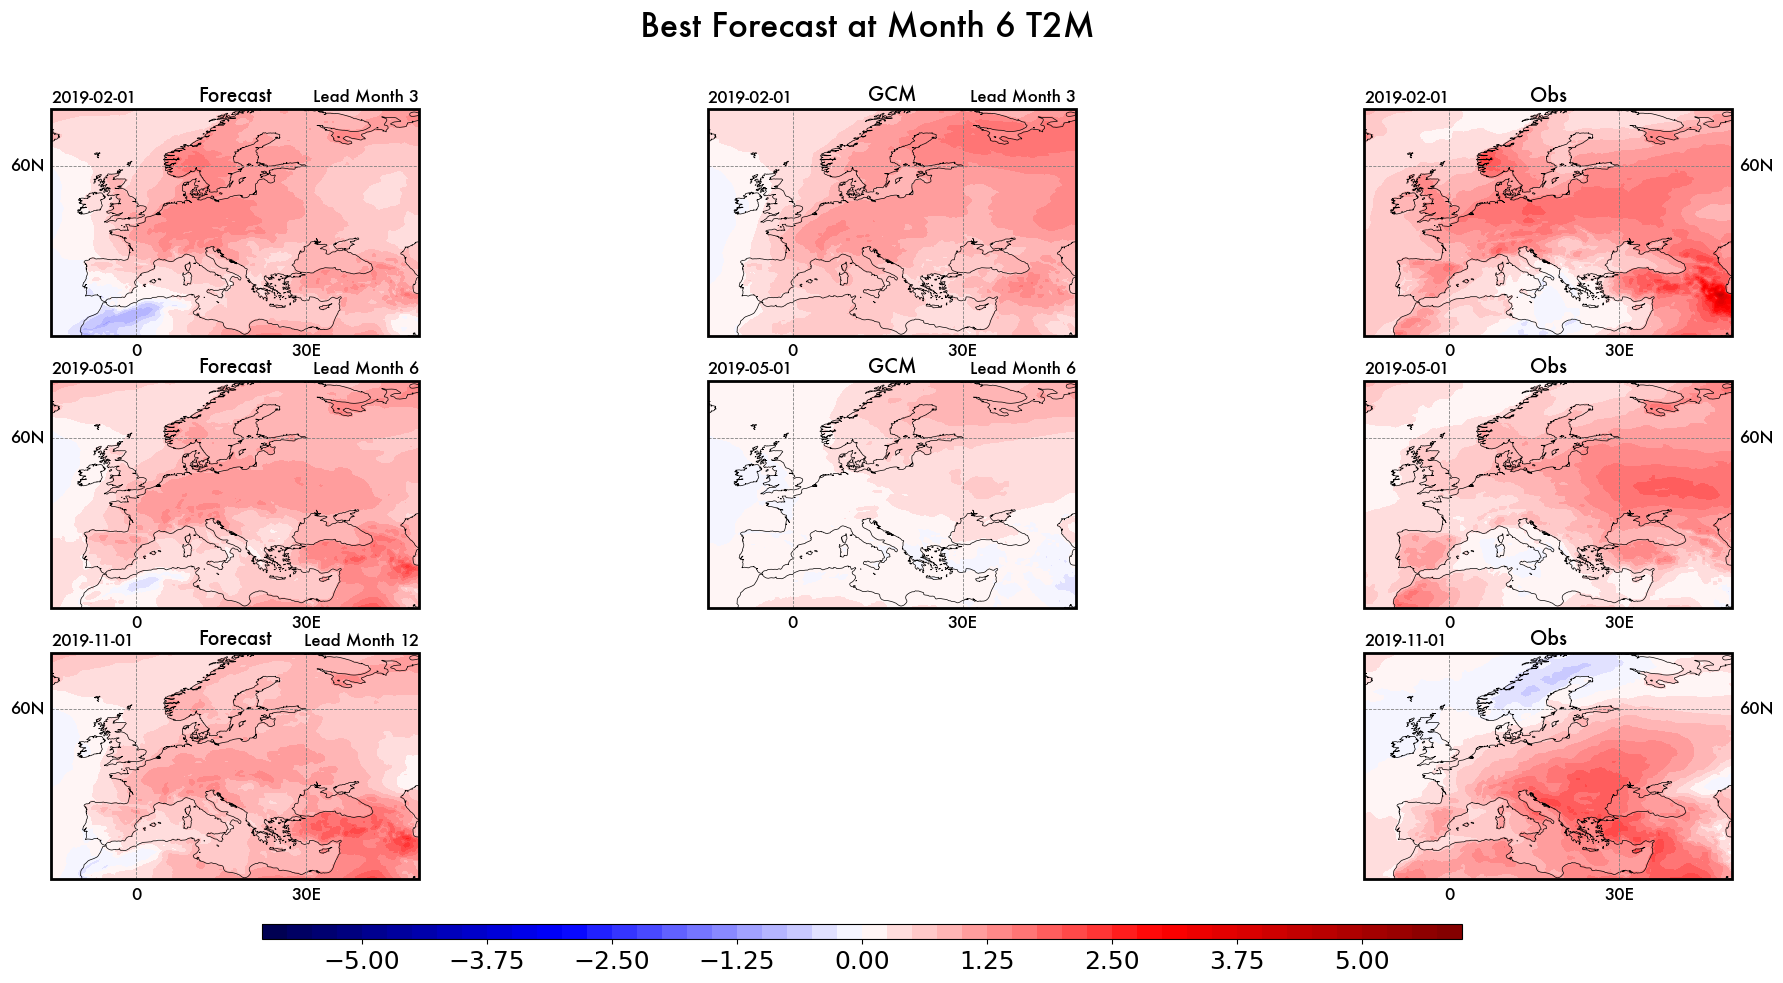

In [69]:
# Best Forecast
cday = 6
im = np.argmin(np.abs(rmsres[cday,Ftind]))
print(im, rmsres[cday,im])
fname = f'BEST{figfilename}.pdf'
# Cont = namedtuple('Contours', 'max min int')
# cont_ = Cont(2, -2, 0.25)
np.arange(cont_.min,cont_.max,cont_.int)
cont=[cont_.min, cont_.max, cont_.int]
this_forecast = str(Ft.time.isel(time=Ftind[im]).data[()]).split('T')[0]
# cont = []

ftmp = zai.select_fcst(this_forecast, Ft)
dtmp = zai.select_fcst(this_forecast, Dt)
vtmp = Obs.sel(time=ftmp.time)

ax = utp.Three_Forecast_plots(ftmp,vtmp, dtmp,  'T2M',  None, cont, this_forecast,\
                   pictimes=[3,6,12], figsize=(24,10), world_projection='Atlantic',\
                   colorbars=False, maintitle=f' Best Forecast at Month {cday} ', picturelabels=None, arealatz=arealatz, arealonz=arealonz, centlon=0,labfile=fname)
   

In [ ]:
# Worst Forecast for Model
# Three forecast

cday = 6
im = np.argmax(np.abs(rmsres[cday,Ftind]))
print(im, rmsres[cday,im])
fname = f'WORST{figfilename}.pdf'# Cont = namedtuple('Contours', 'max min int')
# cont_ = Cont(2, -2, 0.25)
np.arange(cont_.min,cont_.max,cont_.int)
cont=[cont_.min, cont_.max, cont_.int]
this_forecast = str(Ft.time.isel(time=Ftind[im]).data[()]).split('T')[0]
# cont = []

ftmp = zai.select_fcst(this_forecast, Ft)
dtmp = zai.select_fcst(this_forecast, Dt)
vtmp = Obs.sel(time=ftmp.time)

ax = utp.Three_Forecast_plots(ftmp,vtmp, dtmp,  'T2M',  None, cont, this_forecast,\
                   pictimes=[3,6,12], figsize=(24,10), world_projection='Atlantic',\
                   colorbars=False, maintitle=f' Worst Forecast at Month {cday} ', picturelabels=None, arealatz=arealatz, arealonz=arealonz, centlon=0,labfile=fname)
   

11 0.31580466532179574
 Opening figure , 3 rows and 3 cols 

Setting Fixed Contours
 Contouring from  -6   to 6  with interval   0.25
Setting Fixed Contours
 Contouring from  -6   to 6  with interval   0.25
Setting Fixed Contours
 Contouring from  -6   to 6  with interval   0.25
Setting Fixed Contours
 Contouring from  -6   to 6  with interval   0.25
Setting Fixed Contours
 Contouring from  -6   to 6  with interval   0.25
Setting Fixed Contours
 Contouring from  -6   to 6  with interval   0.25
Setting Fixed Contours
 Contouring from  -6   to 6  with interval   0.25
Setting Fixed Contours
 Contouring from  -6   to 6  with interval   0.25
